The analysis focuses on identifying patterns and associations related to booking cancellations, customer characteristics, booking behaviour, hotel type, market segment, deposit type, lead time, seasonality, and other relevant variables.

Part 0 — Project setup
- Import libraries
- Set random seed = 42
- Load hotel_bookings_cleaned.csv
- Verify shape and columns


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import binom
from statsmodels.stats.proportion import proportion_confint

# Reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Plot settings
sns.set_theme()

print("Libraries imported successfully.")
print("Random seed:", RANDOM_SEED)

Libraries imported successfully.
Random seed: 42


In [4]:
# Load cleaned dataset
df = pd.read_csv("../data/processed/hotel_bookings_cleaned.csv")

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (87396, 37)


In [5]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumns:")
for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

Number of rows: 87396
Number of columns: 37

Columns:
1. IsCanceled
2. LeadTime
3. ArrivalDateYear
4. ArrivalDateMonth
5. ArrivalDateWeekNumber
6. ArrivalDateDayOfMonth
7. StaysInWeekendNights
8. StaysInWeekNights
9. Adults
10. Children
11. Babies
12. Meal
13. Country
14. MarketSegment
15. DistributionChannel
16. IsRepeatedGuest
17. PreviousCancellations
18. PreviousBookingsNotCanceled
19. ReservedRoomType
20. AssignedRoomType
21. BookingChanges
22. DepositType
23. Agent
24. Company
25. DaysInWaitingList
26. CustomerType
27. ADR
28. RequiredCarParkingSpaces
29. TotalOfSpecialRequests
30. ReservationStatus
31. ReservationStatusDate
32. Hotel
33. ArrivalDate
34. Season
35. TotalNights
36. TotalGuests
37. LeadTimeBand


Part 1 — Dataset overview
- Number of bookings
- Number of variables
- Hotel distribution
- Cancellation distribution
- Missing-value check


In [6]:
missing_values = df.isna().sum()

missing_summary = (
    missing_values[missing_values > 0]
    .sort_values(ascending=False)
)

if missing_summary.empty:
    print("No missing values found.")
else:
    print(missing_summary)

No missing values found.


In [8]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)
dtype_summary = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values
})

dtype_summary

Number of duplicate rows: 0


,Column,Data Type
0,IsCanceled,int64
1,LeadTime,int64
2,ArrivalDateYear,int64
3,ArrivalDateMonth,str
4,ArrivalDateWeekNumber,int64
5,ArrivalDateDayOfMonth,int64
6,StaysInWeekendNights,int64
7,StaysInWeekNights,int64
8,Adults,int64
9,Children,float64


In [9]:
print("Unique IsCanceled values:")
print(sorted(df["IsCanceled"].unique()))
print("\nCancellation counts:")
print(df["IsCanceled"].value_counts().sort_index())
print("\nCancellation proportions:")
print(
    df["IsCanceled"]
    .value_counts(normalize=True)
    .sort_index()
)
overall_cancellation_rate = df["IsCanceled"].mean()

print(
    f"\nOverall cancellation rate: "
    f"{overall_cancellation_rate:.4f}"
)

print(
    f"Overall cancellation rate: "
    f"{overall_cancellation_rate * 100:.2f}%"
)

Unique IsCanceled values:
[np.int64(0), np.int64(1)]

Cancellation counts:
IsCanceled
0    63371
1    24025
Name: count, dtype: int64

Cancellation proportions:
IsCanceled
0    0.725102
1    0.274898
Name: proportion, dtype: float64

Overall cancellation rate: 0.2749
Overall cancellation rate: 27.49%


In [10]:
dataset_summary = pd.DataFrame({
    "Measure": [
        "Number of bookings",
        "Number of variables",
        "Cancelled bookings",
        "Non-cancelled bookings",
        "Overall cancellation rate"
    ],
    "Value": [
        len(df),
        df.shape[1],
        int(df["IsCanceled"].sum()),
        int((df["IsCanceled"] == 0).sum()),
        f"{df['IsCanceled'].mean() * 100:.2f}%"
    ]
})

dataset_summary

,Measure,Value
0,Number of bookings,87396
1,Number of variables,37
2,Cancelled bookings,24025
3,Non-cancelled bookings,63371
4,Overall cancellation rate,27.49%


Categorical attribute check


In [11]:
categorical_columns = [
    "Hotel",
    "MarketSegment",
    "DistributionChannel",
    "DepositType",
    "CustomerType",
    "Season",
    "LeadTimeBand",
    "IsRepeatedGuest"
]

for column in categorical_columns:
    print("\n" + "=" * 60)
    print(column)
    print("=" * 60)
    print(df[column].value_counts(dropna=False))


Hotel
Hotel
City Hotel      53428
Resort Hotel    33968
Name: count, dtype: int64

MarketSegment
MarketSegment
Online TA        51618
Offline TA/TO    13889
Direct           11804
Groups            4942
Corporate         4212
Complementary      702
Aviation           227
Undefined            2
Name: count, dtype: int64

DistributionChannel
DistributionChannel
TA/TO        69141
Direct       12988
Corporate     5081
GDS            181
Undefined        5
Name: count, dtype: int64

DepositType
DepositType
No Deposit    86251
Non Refund     1038
Refundable      107
Name: count, dtype: int64

CustomerType
CustomerType
Transient          71986
Transient-Party    11727
Contract            3139
Group                544
Name: count, dtype: int64

Season
Season
Summer    29079
Spring    23776
Autumn    18619
Winter    15922
Name: count, dtype: int64

LeadTimeBand
LeadTimeBand
1-3mo    22744
0-7d     18304
3-6mo    18243
1-4wk    16340
6mo+     11765
Name: count, dtype: int64

IsRepeatedGuest
Is

Numerical attribute check


In [12]:
numeric_columns = [
    "LeadTime",
    "ADR",
    "TotalNights",
    "TotalGuests",
    "Adults",
    "Children",
    "Babies",
    "PreviousCancellations",
    "PreviousBookingsNotCanceled",
    "BookingChanges",
    "DaysInWaitingList",
    "TotalOfSpecialRequests"
]

df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
LeadTime,87396.0,79.891368,86.052325,0.0,11.0,49.0,125.0,737.0
ADR,87396.0,106.338229,55.012707,0.0,72.0,98.1,134.0,5400.0
TotalNights,87396.0,3.630658,2.763449,0.0,2.0,3.0,5.0,69.0
TotalGuests,87396.0,2.025253,0.794319,0.0,2.0,2.0,2.0,55.0
Adults,87396.0,1.875795,0.626500,0.0,2.0,2.0,2.0,55.0
Children,87396.0,0.138633,0.455871,0.0,0.0,0.0,0.0,10.0
Babies,87396.0,0.010824,0.113597,0.0,0.0,0.0,0.0,10.0
PreviousCancellations,87396.0,0.030413,0.369145,0.0,0.0,0.0,0.0,26.0
PreviousBookingsNotCanceled,87396.0,0.183990,1.731894,0.0,0.0,0.0,0.0,72.0
BookingChanges,87396.0,0.271603,0.727245,0.0,0.0,0.0,0.0,21.0


In [13]:
print("Years:")
print(sorted(df["ArrivalDateYear"].unique()))

print("\nMonths by year:")

months_by_year = (
    df.groupby("ArrivalDateYear")["ArrivalDateMonth"]
    .unique()
)

for year, months in months_by_year.items():
    print(year, ":", list(months))

Years:
[np.int64(2015), np.int64(2016), np.int64(2017)]

Months by year:
2015 : ['July', 'August', 'September', 'October', 'November', 'December']
2016 : ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
2017 : ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August']


checks

In [14]:
print("Season values:")
print(df["Season"].value_counts())

print("\nLeadTimeBand values:")
print(df["LeadTimeBand"].value_counts())

print("\nTotalNights summary:")
print(df["TotalNights"].describe())

print("\nTotalGuests summary:")
print(df["TotalGuests"].describe())

Season values:
Season
Summer    29079
Spring    23776
Autumn    18619
Winter    15922
Name: count, dtype: int64

LeadTimeBand values:
LeadTimeBand
1-3mo    22744
0-7d     18304
3-6mo    18243
1-4wk    16340
6mo+     11765
Name: count, dtype: int64

TotalNights summary:
count    87396.000000
mean         3.630658
std          2.763449
min          0.000000
25%          2.000000
50%          3.000000
75%          5.000000
max         69.000000
Name: TotalNights, dtype: float64

TotalGuests summary:
count    87396.000000
mean         2.025253
std          0.794319
min          0.000000
25%          2.000000
50%          2.000000
75%          2.000000
max         55.000000
Name: TotalGuests, dtype: float64


Part 2 — Cancellation EDA

1. Cancellation by Hotel
2. Cancellation by Market Segment
3. Cancellation by Deposit Type
4. Cancellation by LeadTimeBand
5. Cancellation by Customer Type
6. Cancellation by Repeated Guest
7. Cancellation by Previous Cancellations

## 1. Cancellation Baseline

Before comparing cancellation behaviour across hotels, market segments, booking channels, or customer characteristics, we first establish the overall cancellation rate in the cleaned dataset.

The variable `IsCanceled` represents cancellation status, where 1 indicates a cancelled booking and 0 indicates a non-cancelled booking.

This overall rate provides a baseline for interpreting the group-level cancellation rates explored in the following sections.

In [15]:
# Overall cancellation baseline

cancellation_counts = (
    df["IsCanceled"]
    .value_counts()
    .sort_index()
)

cancellation_rate = df["IsCanceled"].mean()

print("Cancellation counts:")
print(cancellation_counts)

print(f"\nOverall cancellation rate: {cancellation_rate:.4f}")
print(f"Overall cancellation rate: {cancellation_rate * 100:.2f}%")

Cancellation counts:
IsCanceled
0    63371
1    24025
Name: count, dtype: int64

Overall cancellation rate: 0.2749
Overall cancellation rate: 27.49%


In [16]:
# Create a summary table

cancellation_summary = pd.DataFrame({
    "Status": ["Not Cancelled", "Cancelled"],
    "Bookings": [
        (df["IsCanceled"] == 0).sum(),
        (df["IsCanceled"] == 1).sum()
    ],
})

cancellation_summary["Percentage"] = (
    cancellation_summary["Bookings"]
    / len(df)
    * 100
)

cancellation_summary

,Status,Bookings,Percentage
0,Not Cancelled,63371,72.510184
1,Cancelled,24025,27.489816


## 2. Cancellation by Hotel

**Question:** Is cancellation behaviour different between City Hotel and Resort Hotel?

**Graph:** The bar chart compares the observed cancellation rate for each hotel type. The number of bookings (`n`) is shown for each group, together with 95% confidence intervals for the estimated cancellation proportions.

**Observation:** The cancellation rates of City Hotel and Resort Hotel are compared against the overall cancellation rate established above.

**Possible explanation:** Differences between the two hotel types may be linked to differences in booking composition, market segment, customer characteristics, booking channel, or other factors.

**Statistical question:** Is hotel type statistically associated with cancellation status?

**Interpretation rule:** The observed difference represents an association in this dataset and does not establish that hotel type causes cancellation.

In [17]:
def cancellation_rate_summary(data, group_column):
    """
    Calculate cancellation count, booking count,
    cancellation rate, and 95% Wilson confidence interval.
    """
    
    summary = (
        data.groupby(group_column)["IsCanceled"]
        .agg(
            cancelled="sum",
            n="count"
        )
        .reset_index()
    )

    summary["rate"] = summary["cancelled"] / summary["n"]

    ci_low, ci_high = proportion_confint(
        summary["cancelled"],
        summary["n"],
        alpha=0.05,
        method="wilson"
    )

    summary["ci_low"] = ci_low
    summary["ci_high"] = ci_high

    summary["rate_percent"] = summary["rate"] * 100
    summary["ci_low_percent"] = summary["ci_low"] * 100
    summary["ci_high_percent"] = summary["ci_high"] * 100

    return summary

calculate hotel cancellation rates

In [18]:
hotel_summary = cancellation_rate_summary(
    df,
    "Hotel"
)

hotel_summary

,Hotel,cancelled,n,rate,ci_low,ci_high,rate_percent,ci_low_percent,ci_high_percent
0,City Hotel,16049,53428,0.300386,0.296513,0.304287,30.038557,29.651287,30.428696
1,Resort Hotel,7976,33968,0.234809,0.230332,0.239347,23.480923,23.033167,23.934677


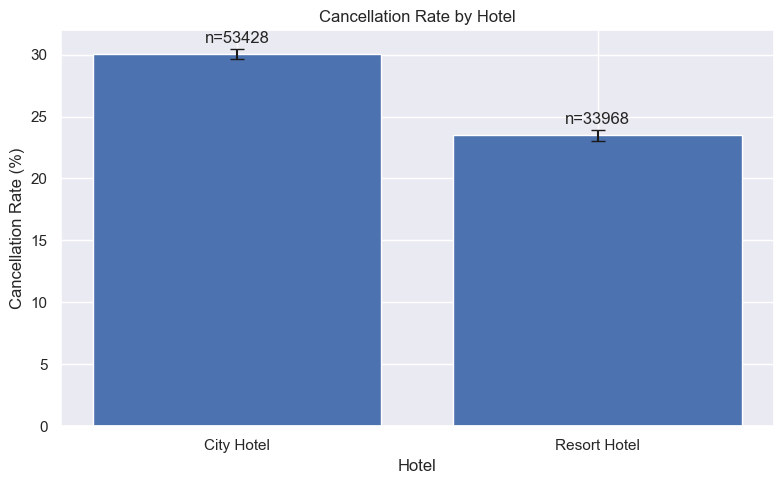

In [19]:
plt.figure(figsize=(8, 5))

x = np.arange(len(hotel_summary))

rates = hotel_summary["rate_percent"].values

lower_error = (
    hotel_summary["rate_percent"]
    - hotel_summary["ci_low_percent"]
).values

upper_error = (
    hotel_summary["ci_high_percent"]
    - hotel_summary["rate_percent"]
).values

plt.bar(
    x,
    rates,
    yerr=[lower_error, upper_error],
    capsize=5
)

plt.xticks(
    x,
    hotel_summary["Hotel"]
)

plt.ylabel("Cancellation Rate (%)")
plt.xlabel("Hotel")
plt.title("Cancellation Rate by Hotel")

# Add n above each bar
for i, row in hotel_summary.iterrows():
    plt.text(
        i,
        row["rate_percent"] + upper_error[i] + 0.5,
        f"n={row['n']}",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    "../outputs/figures/p2_cancellation_rate_by_hotel.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

### Interpretation

**Observation:**  
The observed cancellation rate is higher for City Hotel than for Resort Hotel. City Hotel has a cancellation rate of approximately 30%, compared with approximately 23–24% for Resort Hotel. The City Hotel group also contains more bookings than the Resort Hotel group.

**Possible explanation:**  
The difference may be linked to differences in booking composition, market segment, booking channel, customer characteristics, or other factors associated with the two hotel types.

**Statistical question:**  
Is hotel type statistically associated with cancellation status?

**Interpretation:**  
The observed difference represents an association in this dataset and does not establish that hotel type causes cancellation.

## 3. Cancellation by Market Segment

**Question:** Is cancellation behaviour different across market segments?

**Graph:** The bar chart compares the observed cancellation rate across market segments, with the number of bookings and 95% confidence intervals shown for each group.

**Observation:** The cancellation rates vary across market segments, although the reliability of the estimates depends on the number of bookings in each group.

**Possible explanation:** Market segments may represent different booking patterns, customer groups, or booking channels that are associated with different cancellation behaviour.

**Statistical question:** Is market segment statistically associated with cancellation status?

**Note:** The `Undefined` market segment contains only two bookings, so its estimated cancellation rate should be interpreted with extreme caution.

In [20]:
market_segment_summary = cancellation_rate_summary(
    df,
    "MarketSegment"
)

market_segment_summary

,MarketSegment,cancelled,n,rate,ci_low,ci_high,rate_percent,ci_low_percent,ci_high_percent
0,Aviation,45,227,0.198238,0.151586,0.254933,19.823789,15.158606,25.493303
1,Complementary,88,702,0.125356,0.102882,0.151908,12.535613,10.288241,15.190775
2,Corporate,510,4212,0.121083,0.111574,0.131281,12.108262,11.157445,13.128132
3,Direct,1737,11804,0.147154,0.140878,0.153659,14.715351,14.087752,15.365908
4,Groups,1335,4942,0.270134,0.257936,0.282688,27.013355,25.793598,28.268820
5,Offline TA/TO,2063,13889,0.148535,0.142718,0.154546,14.853481,14.271762,15.454637
6,Online TA,18245,51618,0.353462,0.349349,0.357597,35.346197,34.934904,35.759671
7,Undefined,2,2,1.000000,0.342380,1.000000,100.000000,34.238023,100.000000


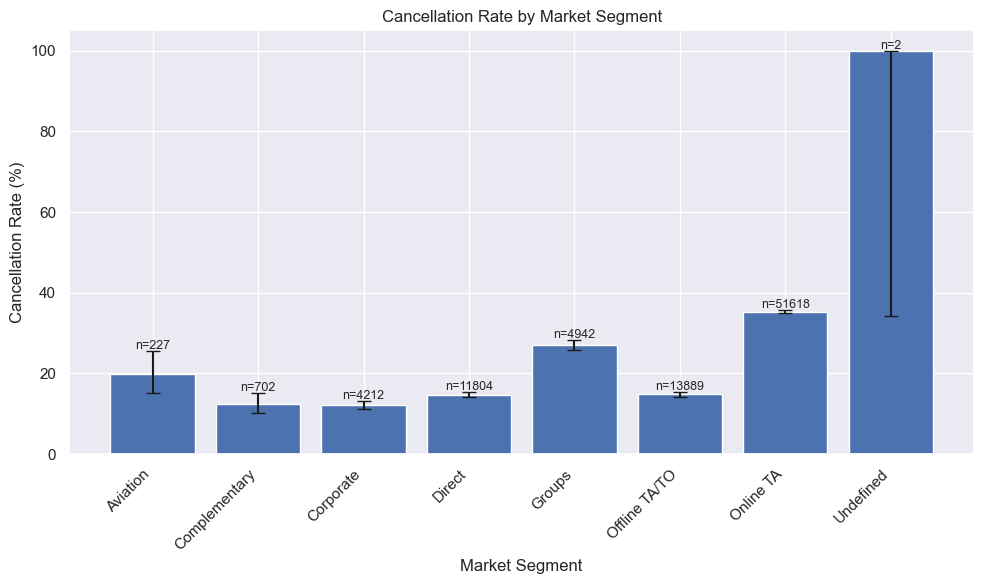

In [21]:
plt.figure(figsize=(10, 6))

x = np.arange(len(market_segment_summary))

rates = market_segment_summary["rate_percent"].values

lower_error = (
    market_segment_summary["rate_percent"]
    - market_segment_summary["ci_low_percent"]
).values

upper_error = (
    market_segment_summary["ci_high_percent"]
    - market_segment_summary["rate_percent"]
).values

plt.bar(
    x,
    rates,
    yerr=[lower_error, upper_error],
    capsize=5
)

plt.xticks(
    x,
    market_segment_summary["MarketSegment"],
    rotation=45,
    ha="right"
)

plt.ylabel("Cancellation Rate (%)")
plt.xlabel("Market Segment")
plt.title("Cancellation Rate by Market Segment")

# Add booking count above each bar
for i, row in market_segment_summary.iterrows():
    plt.text(
        i,
        row["rate_percent"] + upper_error[i] + 0.5,
        f"n={row['n']}",
        ha="center",
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    "../outputs/figures/p2_cancellation_rate_by_market_segment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

### Interpretation

**Observation:**  
Cancellation rates vary across market segments. Online TA has a relatively high observed cancellation rate, while Groups also shows a comparatively high rate. Direct, Offline TA/TO, Corporate, Complementary, and Aviation have lower observed cancellation rates.

The `Undefined` category shows a 100% cancellation rate, but it contains only 2 bookings and therefore provides very little evidence about the behaviour of this segment.

**Possible explanation:**  
Differences between market segments may be linked to differences in booking behaviour, customer composition, booking arrangements, or distribution channels.

**Statistical question:**  
Is market segment statistically associated with cancellation status?

**Important note:**  
The `Undefined` market segment contains only two observations. Its estimated cancellation rate and confidence interval should therefore be interpreted with extreme caution.

**Interpretation:**  
The observed differences represent associations in the dataset and do not establish that market segment causes cancellation.

## 4. Cancellation by Deposit Type

**Question:** Is cancellation behaviour different across deposit types?

**Graph:** The bar chart compares the observed cancellation rate for each deposit type. The number of bookings (`n`) and 95% confidence intervals are shown for each group.

**Observation:** The cancellation rates are compared across the available deposit types, while considering the number of bookings contributing to each estimate.

**Possible explanation:** Differences in cancellation rates may be linked to differences in booking conditions associated with the deposit types.

**Statistical question:** Is deposit type statistically associated with cancellation status?

**Interpretation:** The observed relationship represents an association in the dataset and does not establish that deposit type causes cancellation.

In [22]:
deposit_summary = cancellation_rate_summary(
    df,
    "DepositType"
)

deposit_summary

,DepositType,cancelled,n,rate,ci_low,ci_high,rate_percent,ci_low_percent,ci_high_percent
0,No Deposit,23016,86251,0.266849,0.263908,0.269811,26.684908,26.390765,26.981127
1,Non Refund,983,1038,0.947013,0.931664,0.959067,94.701349,93.166361,95.906693
2,Refundable,26,107,0.242991,0.171559,0.332237,24.299065,17.155857,33.223721


order the categories

In [23]:
deposit_summary = (
    deposit_summary
    .sort_values("rate_percent", ascending=False)
    .reset_index(drop=True)
)

deposit_summary

,DepositType,cancelled,n,rate,ci_low,ci_high,rate_percent,ci_low_percent,ci_high_percent
0,Non Refund,983,1038,0.947013,0.931664,0.959067,94.701349,93.166361,95.906693
1,No Deposit,23016,86251,0.266849,0.263908,0.269811,26.684908,26.390765,26.981127
2,Refundable,26,107,0.242991,0.171559,0.332237,24.299065,17.155857,33.223721


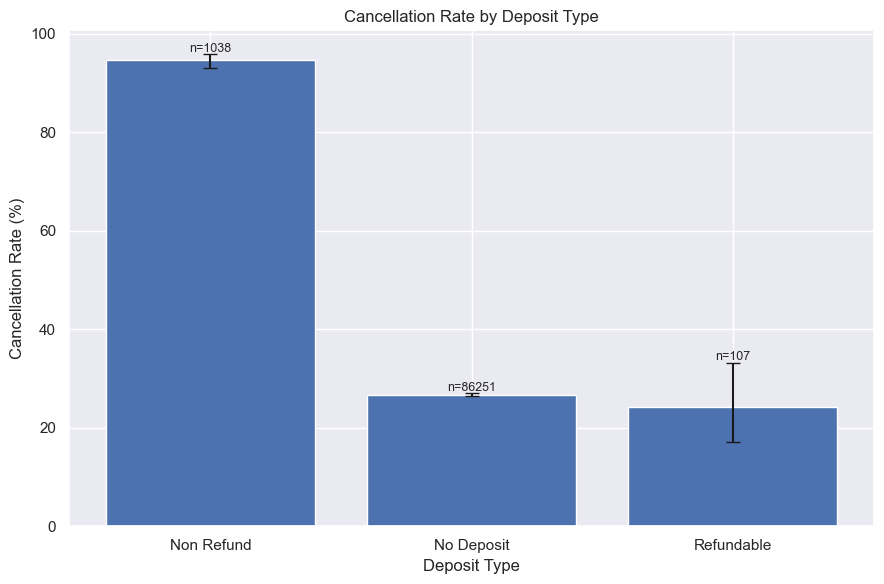

In [24]:
plt.figure(figsize=(9, 6))

x = np.arange(len(deposit_summary))

rates = deposit_summary["rate_percent"].values

lower_error = (
    deposit_summary["rate_percent"]
    - deposit_summary["ci_low_percent"]
).values

upper_error = (
    deposit_summary["ci_high_percent"]
    - deposit_summary["rate_percent"]
).values

plt.bar(
    x,
    rates,
    yerr=[lower_error, upper_error],
    capsize=5
)

plt.xticks(
    x,
    deposit_summary["DepositType"]
)

plt.ylabel("Cancellation Rate (%)")
plt.xlabel("Deposit Type")
plt.title("Cancellation Rate by Deposit Type")

for i, row in deposit_summary.iterrows():
    plt.text(
        i,
        row["rate_percent"] + upper_error[i] + 0.5,
        f"n={row['n']}",
        ha="center",
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    "../outputs/figures/p2_cancellation_rate_by_deposit_type.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

### Interpretation

**Observation:**  
The observed cancellation rate differs substantially across deposit types. Non Refund bookings have a much higher cancellation rate than No Deposit and Refundable bookings. The No Deposit group contains the vast majority of bookings, while the Refundable group is much smaller.

**Possible explanation:**  
Different deposit arrangements may be associated with different booking conditions and customer behaviour.

**Statistical question:**  
Is deposit type statistically associated with cancellation status?

**Important note:**  
The Refundable category contains relatively few bookings compared with No Deposit, so its estimated cancellation rate has greater uncertainty.

**Interpretation:**  
The observed relationship represents an association in the dataset and does not establish that deposit type causes cancellation.

## 5. Cancellation by Lead Time Band

**Question:** Does cancellation behaviour differ across lead-time bands?

**Graph:** The bar chart compares the observed cancellation rate across the predefined `LeadTimeBand` categories. The number of bookings and 95% confidence intervals are shown for each band.

**Observation:** The cancellation rate is compared across bookings made at different lead-time ranges.

**Possible explanation:** Customers booking further in advance may have different booking patterns or circumstances than customers making reservations closer to the arrival date.

**Statistical question:** Is lead-time band statistically associated with cancellation status?

**Interpretation:** The observed pattern represents an association between lead-time band and cancellation status and does not establish that booking further in advance causes cancellation.

In [25]:
print(df["LeadTimeBand"].unique())

<StringArray>
['6mo+', '0-7d', '1-4wk', '1-3mo', '3-6mo']
Length: 5, dtype: str


reordereing leadtimeband


In [26]:
lead_time_order = [
    "0-7d",
    "1-4wk",
    "1-3mo",
    "3-6mo",
    "6mo+"
]

df["LeadTimeBand"] = pd.Categorical(
    df["LeadTimeBand"],
    categories=lead_time_order,
    ordered=True
)

print(df["LeadTimeBand"].value_counts().sort_index())

LeadTimeBand
0-7d     18304
1-4wk    16340
1-3mo    22744
3-6mo    18243
6mo+     11765
Name: count, dtype: int64


In [27]:
lead_time_summary = cancellation_rate_summary(
    df,
    "LeadTimeBand"
)

lead_time_summary

,LeadTimeBand,cancelled,n,rate,ci_low,ci_high,rate_percent,ci_low_percent,ci_high_percent
0,0-7d,1543,18304,0.084299,0.080360,0.088411,8.429851,8.036025,8.841123
1,1-4wk,4145,16340,0.253672,0.247059,0.260401,25.367197,24.705891,26.040083
2,1-3mo,7280,22744,0.320084,0.314052,0.326177,32.008442,31.405242,32.617718
3,3-6mo,6382,18243,0.349833,0.342944,0.356784,34.983281,34.294450,35.678435
4,6mo+,4675,11765,0.397365,0.388557,0.406240,39.736507,38.855747,40.623967


sorting after reordering

In [28]:
lead_time_summary["LeadTimeBand"] = pd.Categorical(
    lead_time_summary["LeadTimeBand"],
    categories=lead_time_order,
    ordered=True
)

lead_time_summary = (
    lead_time_summary
    .sort_values("LeadTimeBand")
    .reset_index(drop=True)
)

lead_time_summary

,LeadTimeBand,cancelled,n,rate,ci_low,ci_high,rate_percent,ci_low_percent,ci_high_percent
0,0-7d,1543,18304,0.084299,0.080360,0.088411,8.429851,8.036025,8.841123
1,1-4wk,4145,16340,0.253672,0.247059,0.260401,25.367197,24.705891,26.040083
2,1-3mo,7280,22744,0.320084,0.314052,0.326177,32.008442,31.405242,32.617718
3,3-6mo,6382,18243,0.349833,0.342944,0.356784,34.983281,34.294450,35.678435
4,6mo+,4675,11765,0.397365,0.388557,0.406240,39.736507,38.855747,40.623967


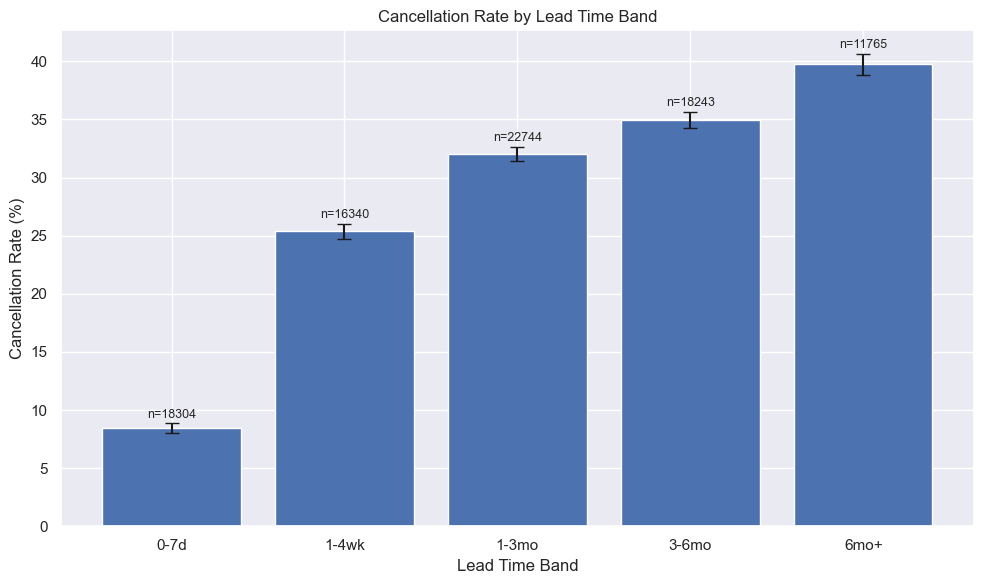

In [29]:
plt.figure(figsize=(10, 6))

x = np.arange(len(lead_time_summary))

rates = lead_time_summary["rate_percent"].values

lower_error = (
    lead_time_summary["rate_percent"]
    - lead_time_summary["ci_low_percent"]
).values

upper_error = (
    lead_time_summary["ci_high_percent"]
    - lead_time_summary["rate_percent"]
).values

plt.bar(
    x,
    rates,
    yerr=[lower_error, upper_error],
    capsize=5
)

plt.xticks(
    x,
    lead_time_summary["LeadTimeBand"]
)

plt.ylabel("Cancellation Rate (%)")
plt.xlabel("Lead Time Band")
plt.title("Cancellation Rate by Lead Time Band")

for i, row in lead_time_summary.iterrows():
    plt.text(
        i,
        row["rate_percent"] + upper_error[i] + 0.5,
        f"n={row['n']}",
        ha="center",
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    "../outputs/figures/p2_cancellation_rate_by_lead_time_band.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

### Interpretation

**Observation:**  
The observed cancellation rate increases across the lead-time bands. Bookings made 0–7 days before arrival have the lowest cancellation rate at approximately 8%, while bookings made 6 months or more in advance have the highest rate at approximately 40%. The intermediate bands show a gradual increase, from approximately 25% for 1–4 weeks to approximately 32% for 1–3 months and approximately 35% for 3–6 months.

**Possible explanation:**  
Bookings made further in advance may be associated with different booking behaviour or circumstances, giving customers more time for their plans to change before the arrival date.

**Statistical question:**  
Is lead-time band statistically associated with cancellation status?

**Interpretation:**  
The observed pattern shows an association between lead-time band and cancellation status. It does not establish that a longer lead time causes cancellation.

## 6. Cancellation by Customer Type

**Question:** Is cancellation behaviour different across customer types?

**Graph:** The bar chart compares the observed cancellation rate across customer types. The number of bookings (`n`) and 95% confidence intervals are shown for each group.


**Possible explanation:**  
Different customer types may have different booking patterns, travel purposes, or booking arrangements that are associated with different cancellation behaviour.

**Statistical question:**  
Is customer type statistically associated with cancellation status?

**Interpretation:**  
The observed differences represent associations in the dataset and do not establish that customer type causes cancellation.

In [30]:
print(df["CustomerType"].value_counts())

CustomerType
Transient          71986
Transient-Party    11727
Contract            3139
Group                544
Name: count, dtype: int64


In [31]:
print("\nCustomer type categories:")
print(df["CustomerType"].unique())


Customer type categories:
<StringArray>
['Transient', 'Contract', 'Transient-Party', 'Group']
Length: 4, dtype: str


In [32]:
customer_type_summary = cancellation_rate_summary(
    df,
    "CustomerType"
)

customer_type_summary

,CustomerType,cancelled,n,rate,ci_low,ci_high,rate_percent,ci_low_percent,ci_high_percent
0,Contract,512,3139,0.163109,0.150598,0.176445,16.310927,15.059752,17.644458
1,Group,54,544,0.099265,0.076878,0.127271,9.926471,7.687850,12.727082
2,Transient,21672,71986,0.301059,0.297718,0.304420,30.105854,29.771826,30.442005
3,Transient-Party,1787,11727,0.152383,0.145993,0.159002,15.238339,14.599265,15.900179


In [33]:
customer_type_summary = (
    customer_type_summary
    .sort_values("rate_percent", ascending=False)
    .reset_index(drop=True)
)

customer_type_summary

,CustomerType,cancelled,n,rate,ci_low,ci_high,rate_percent,ci_low_percent,ci_high_percent
0,Transient,21672,71986,0.301059,0.297718,0.304420,30.105854,29.771826,30.442005
1,Contract,512,3139,0.163109,0.150598,0.176445,16.310927,15.059752,17.644458
2,Transient-Party,1787,11727,0.152383,0.145993,0.159002,15.238339,14.599265,15.900179
3,Group,54,544,0.099265,0.076878,0.127271,9.926471,7.687850,12.727082


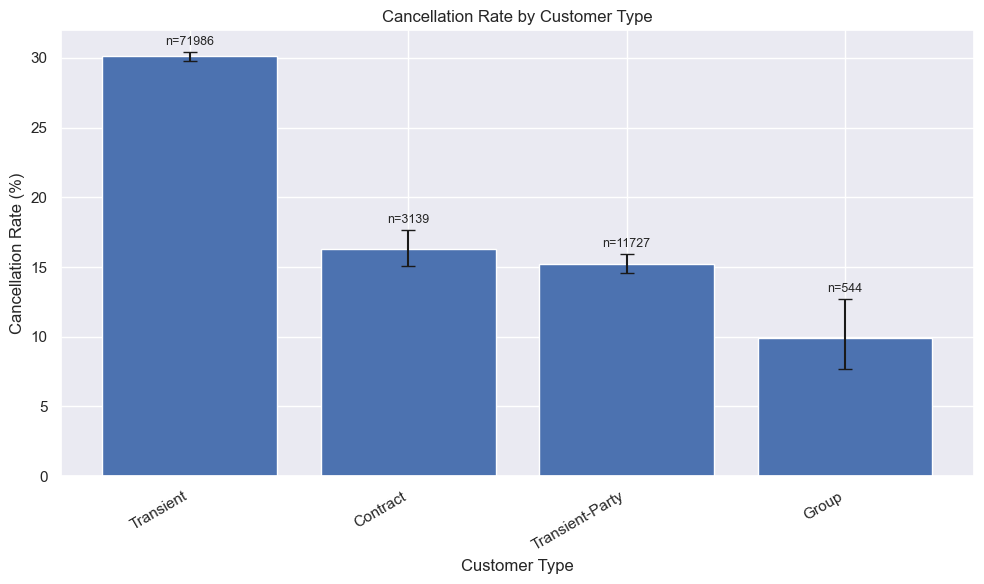

In [34]:
plt.figure(figsize=(10, 6))

x = np.arange(len(customer_type_summary))

rates = customer_type_summary["rate_percent"].values

lower_error = (
    customer_type_summary["rate_percent"]
    - customer_type_summary["ci_low_percent"]
).values

upper_error = (
    customer_type_summary["ci_high_percent"]
    - customer_type_summary["rate_percent"]
).values

plt.bar(
    x,
    rates,
    yerr=[lower_error, upper_error],
    capsize=5
)

plt.xticks(
    x,
    customer_type_summary["CustomerType"],
    rotation=30,
    ha="right"
)

plt.ylabel("Cancellation Rate (%)")
plt.xlabel("Customer Type")
plt.title("Cancellation Rate by Customer Type")

for i, row in customer_type_summary.iterrows():
    plt.text(
        i,
        row["rate_percent"] + upper_error[i] + 0.5,
        f"n={row['n']}",
        ha="center",
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    "../outputs/figures/p2_cancellation_rate_by_customer_type.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

### Interpretation

**Observation:**  
The observed cancellation rate differs across customer types. Transient bookings have the highest cancellation rate at approximately 30%, followed by Contract bookings at approximately 16% and Transient-Party bookings at approximately 15%. Group bookings have the lowest observed cancellation rate at approximately 10%. Transient bookings also make up the largest group, with 71,986 bookings, while Group bookings have a much smaller sample size of 544.

**Possible explanation:**  
Different customer types may have different booking patterns, travel purposes, or booking arrangements that are associated with different cancellation behaviour.

**Statistical question:**  
Is customer type statistically associated with cancellation status?

**Interpretation:**  
The observed differences represent associations in the dataset and do not establish that customer type causes cancellation.

## 7. Cancellation by Repeated Guest Status

**Question:** Is cancellation behaviour different between repeated and non-repeated guests?

**Graph:** The bar chart compares the observed cancellation rate for repeated and non-repeated guests. The number of bookings (`n`) and 95% confidence intervals are shown for each group.


**Possible explanation:**  
Repeated and non-repeated guests may have different booking histories or booking behaviours that are associated with different cancellation patterns.

**Statistical question:**  
Is repeated-guest status statistically associated with cancellation status?

**Interpretation:**  
The observed relationship represents an association in the dataset and does not establish that being a repeated guest causes or prevents cancellation.

In [35]:
print(df["IsRepeatedGuest"].value_counts())

IsRepeatedGuest
0    83981
1     3415
Name: count, dtype: int64


In [36]:
print(df["IsRepeatedGuest"].unique())

[0 1]


In [37]:
repeated_guest_summary = cancellation_rate_summary(
    df,
    "IsRepeatedGuest"
)

repeated_guest_summary

,IsRepeatedGuest,cancelled,n,rate,ci_low,ci_high,rate_percent,ci_low_percent,ci_high_percent
0,0,23764,83981,0.282969,0.279932,0.286025,28.296877,27.993228,28.602510
1,1,261,3415,0.076428,0.067985,0.085822,7.642753,6.798503,8.582189


In [38]:
repeated_guest_summary["GuestType"] = (
    repeated_guest_summary["IsRepeatedGuest"]
    .map({
        0: "Non-Repeated Guest",
        1: "Repeated Guest"
    })
)

repeated_guest_summary

,IsRepeatedGuest,cancelled,n,rate,ci_low,ci_high,rate_percent,ci_low_percent,ci_high_percent,GuestType
0,0,23764,83981,0.282969,0.279932,0.286025,28.296877,27.993228,28.602510,Non-Repeated Guest
1,1,261,3415,0.076428,0.067985,0.085822,7.642753,6.798503,8.582189,Repeated Guest


In [39]:
guest_order = [
    "Non-Repeated Guest",
    "Repeated Guest"
]

repeated_guest_summary["GuestType"] = pd.Categorical(
    repeated_guest_summary["GuestType"],
    categories=guest_order,
    ordered=True
)

repeated_guest_summary = (
    repeated_guest_summary
    .sort_values("GuestType")
    .reset_index(drop=True)
)

repeated_guest_summary

,IsRepeatedGuest,cancelled,n,rate,ci_low,ci_high,rate_percent,ci_low_percent,ci_high_percent,GuestType
0,0,23764,83981,0.282969,0.279932,0.286025,28.296877,27.993228,28.602510,Non-Repeated Guest
1,1,261,3415,0.076428,0.067985,0.085822,7.642753,6.798503,8.582189,Repeated Guest


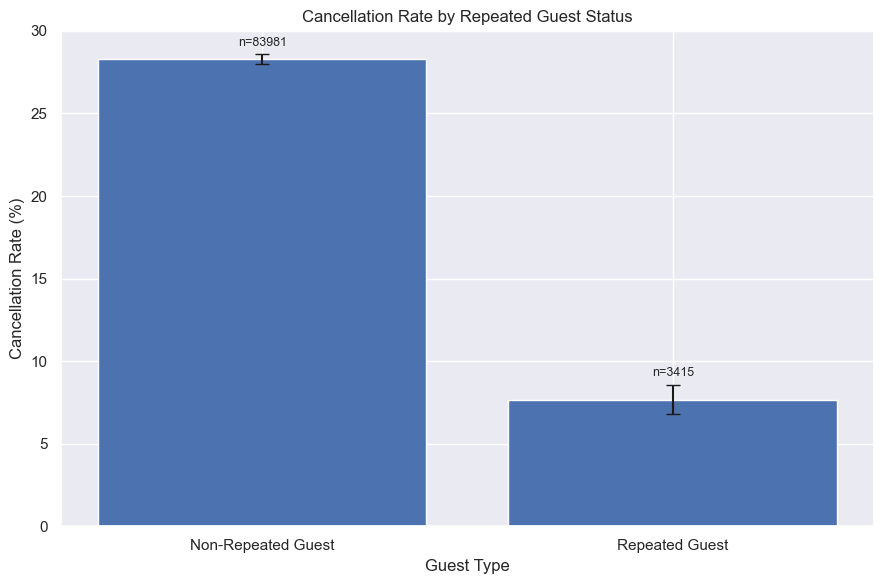

In [41]:
plt.figure(figsize=(9, 6))

x = np.arange(len(repeated_guest_summary))

rates = repeated_guest_summary["rate_percent"].values

lower_error = (
    repeated_guest_summary["rate_percent"]
    - repeated_guest_summary["ci_low_percent"]
).values

upper_error = (
    repeated_guest_summary["ci_high_percent"]
    - repeated_guest_summary["rate_percent"]
).values

plt.bar(
    x,
    rates,
    yerr=[lower_error, upper_error],
    capsize=5
)

plt.xticks(
    x,
    repeated_guest_summary["GuestType"]
)

plt.ylabel("Cancellation Rate (%)")
plt.xlabel("Guest Type")
plt.title("Cancellation Rate by Repeated Guest Status")

for i, row in repeated_guest_summary.iterrows():
    plt.text(
        i,
        row["rate_percent"] + upper_error[i] + 0.5,
        f"n={row['n']}",
        ha="center",
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    "../outputs/figures/p2_cancellation_rate_by_repeated_guest.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

### Interpretation

**Observation:**  
The observed cancellation rate is substantially higher for non-repeated guests than for repeated guests. Non-repeated guests have a cancellation rate of approximately 28.3%, compared with approximately 7.6% for repeated guests. The dataset contains 83,981 non-repeated guest bookings and 3,415 repeated guest bookings, and the 95% confidence intervals for the two groups are clearly separated.

**Possible explanation:**  
Repeated guests may have different booking histories or booking behaviour that is associated with lower cancellation rates compared with non-repeated guests.

**Statistical question:**  
Is repeated-guest status statistically associated with cancellation status?

**Interpretation:**  
The observed relationship represents an association between repeated-guest status and cancellation status. It does not establish that being a repeated guest causes a lower cancellation rate.

## 8. Cancellation by Previous Cancellation History

**Question:** Is cancellation behaviour different for bookings from customers with and without a history of previous cancellations?

**Graph:** The bar chart compares the observed cancellation rate between bookings with no previous cancellations and bookings associated with at least one previous cancellation. The number of bookings (`n`) and 95% confidence intervals are shown for each group.


**Possible explanation:**  
Customers with a history of previous cancellations may have booking behaviour that is associated with different cancellation patterns.

**Statistical question:**  
Is previous cancellation history statistically associated with the current booking's cancellation status?

**Interpretation:**  
The observed relationship represents an association in the dataset and does not establish that previous cancellation history causes a current booking to be cancelled.

In [42]:
print(df["PreviousCancellations"].value_counts().sort_index())

PreviousCancellations
0     85711
1      1407
2       112
3        61
4        30
5        19
6        17
11       27
13        4
14        1
19        1
21        1
24        2
25        2
26        1
Name: count, dtype: int64


In [43]:
print(
    "\nBookings with previous cancellations:",
    (df["PreviousCancellations"] > 0).sum()
)

print(
    "Bookings with no previous cancellations:",
    (df["PreviousCancellations"] == 0).sum()
)


Bookings with previous cancellations: 1685
Bookings with no previous cancellations: 85711


In [44]:
df["PreviousCancellationHistory"] = np.where(
    df["PreviousCancellations"] > 0,
    "At Least One Previous Cancellation",
    "No Previous Cancellations"
)

print(
    df["PreviousCancellationHistory"].value_counts()
)

PreviousCancellationHistory
No Previous Cancellations             85711
At Least One Previous Cancellation     1685
Name: count, dtype: int64


In [45]:
previous_cancellation_summary = cancellation_rate_summary(
    df,
    "PreviousCancellationHistory"
)

previous_cancellation_summary

,PreviousCancellationHistory,cancelled,n,rate,ci_low,ci_high,rate_percent,ci_low_percent,ci_high_percent
0,At Least One Previous Cancellation,1144,1685,0.678932,0.656254,0.700796,67.893175,65.625384,70.079566
1,No Previous Cancellations,22881,85711,0.266955,0.264004,0.269927,26.695523,26.400421,26.992715


In [46]:
previous_cancellation_order = [
    "No Previous Cancellations",
    "At Least One Previous Cancellation"
]

previous_cancellation_summary["PreviousCancellationHistory"] = pd.Categorical(
    previous_cancellation_summary["PreviousCancellationHistory"],
    categories=previous_cancellation_order,
    ordered=True
)

previous_cancellation_summary = (
    previous_cancellation_summary
    .sort_values("PreviousCancellationHistory")
    .reset_index(drop=True)
)

previous_cancellation_summary

,PreviousCancellationHistory,cancelled,n,rate,ci_low,ci_high,rate_percent,ci_low_percent,ci_high_percent
0,No Previous Cancellations,22881,85711,0.266955,0.264004,0.269927,26.695523,26.400421,26.992715
1,At Least One Previous Cancellation,1144,1685,0.678932,0.656254,0.700796,67.893175,65.625384,70.079566


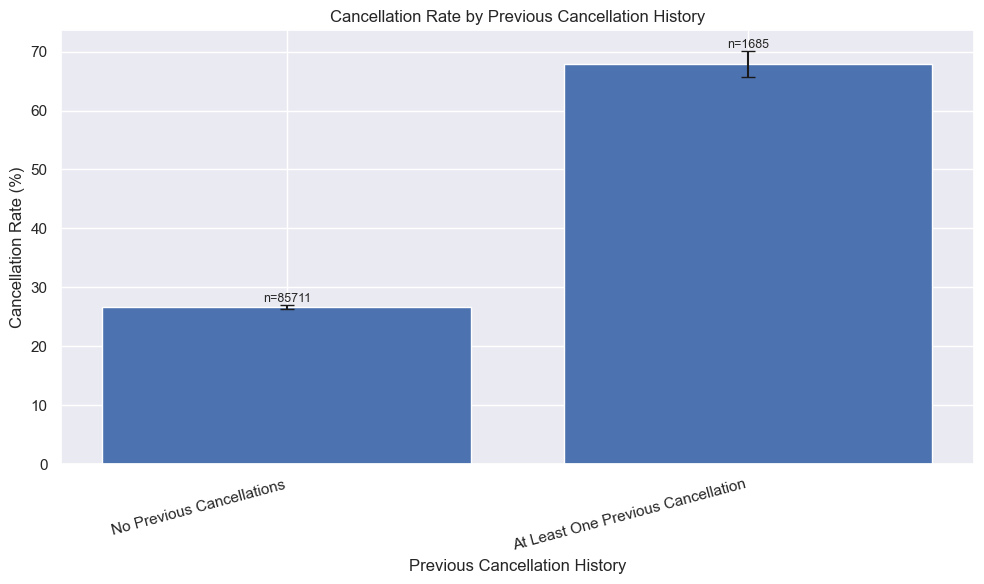

In [47]:
plt.figure(figsize=(10, 6))

x = np.arange(len(previous_cancellation_summary))

rates = previous_cancellation_summary["rate_percent"].values

lower_error = (
    previous_cancellation_summary["rate_percent"]
    - previous_cancellation_summary["ci_low_percent"]
).values

upper_error = (
    previous_cancellation_summary["ci_high_percent"]
    - previous_cancellation_summary["rate_percent"]
).values

plt.bar(
    x,
    rates,
    yerr=[lower_error, upper_error],
    capsize=5
)

plt.xticks(
    x,
    previous_cancellation_summary["PreviousCancellationHistory"],
    rotation=15,
    ha="right"
)

plt.ylabel("Cancellation Rate (%)")
plt.xlabel("Previous Cancellation History")
plt.title("Cancellation Rate by Previous Cancellation History")

for i, row in previous_cancellation_summary.iterrows():
    plt.text(
        i,
        row["rate_percent"] + upper_error[i] + 0.5,
        f"n={row['n']}",
        ha="center",
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    "../outputs/figures/p2_cancellation_rate_by_previous_cancellations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

### Interpretation

**Observation:**  
The observed cancellation rate is substantially higher for bookings associated with customers who have at least one previous cancellation. The cancellation rate is approximately 67.9% for this group, compared with approximately 26.7% for bookings with no previous cancellation history. The group with no previous cancellations contains 85,711 bookings, while the group with at least one previous cancellation contains 1,685 bookings.

**Possible explanation:**  
Customers with a history of previous cancellations may have booking behaviour that is associated with a higher likelihood of cancelling subsequent bookings.

**Statistical question:**  
Is previous cancellation history statistically associated with the current booking's cancellation status?

**Interpretation:**  
The observed relationship represents a strong association between previous cancellation history and current cancellation status. It does not establish that previous cancellations cause a future booking to be cancelled.

Part 3 — Time / seasonality
- Cancellation by arrival month
- Booking count by month
- Season
- Year
- Proper month ordering
- July/August fair year comparison
- Explanation of the 2015/2016/2017 unequal month coverage

In [48]:
print(df["ArrivalDateMonth"].value_counts())

ArrivalDateMonth
August       11257
July         10057
May           8355
April         7908
June          7765
March         7513
October       6934
September     6690
February      6098
December      5131
November      4995
January       4693
Name: count, dtype: int64


In [49]:
month_order = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December"
]

df["ArrivalDateMonth"] = pd.Categorical(
    df["ArrivalDateMonth"],
    categories=month_order,
    ordered=True
)

## 9. Cancellation by Arrival Month

**Question:** Does the observed cancellation rate vary across arrival months?

**Graph:** The bar chart compares the observed cancellation rate across arrival months in chronological order. The number of bookings (`n`) and 95% confidence intervals are shown for each month.



**Possible explanation:**  
Differences in cancellation rates across arrival months may be linked to differences in booking patterns, travel periods, or customer behaviour during different parts of the year.

**Statistical question:**  
Is arrival month statistically associated with cancellation status?

**Important note:**  
The dataset does not contain the same months in every year. The available periods are July–December for 2015, January–December for 2016, and January–August for 2017. Therefore, monthly patterns should not automatically be interpreted as year-to-year changes.

**Interpretation:**  
The observed monthly differences represent associations in the dataset and do not establish that a particular month causes cancellation.

In [50]:
month_summary = cancellation_rate_summary(
    df,
    "ArrivalDateMonth"
)

month_summary

,ArrivalDateMonth,cancelled,n,rate,ci_low,ci_high,rate_percent,ci_low_percent,ci_high_percent
0,January,1038,4693,0.221180,0.209537,0.233280,22.118048,20.953671,23.328034
1,February,1415,6098,0.232043,0.221619,0.242805,23.204329,22.161883,24.280515
2,March,1830,7513,0.243578,0.234004,0.253413,24.357780,23.400439,25.341329
3,April,2409,7908,0.304628,0.294581,0.314865,30.462822,29.458112,31.486504
4,May,2442,8355,0.292280,0.282625,0.302126,29.228007,28.262505,30.212602
5,June,2354,7765,0.303155,0.293032,0.313473,30.315518,29.303159,31.347344
6,July,3198,10057,0.317987,0.308957,0.327157,31.798747,30.895690,32.715704
7,August,3623,11257,0.321844,0.313276,0.330534,32.184419,31.327595,33.053397
8,September,1642,6690,0.245441,0.235277,0.255897,24.544096,23.527668,25.589741
9,October,1642,6934,0.236804,0.226945,0.246954,23.680415,22.694540,24.695437


In [51]:
month_summary["ArrivalDateMonth"] = pd.Categorical(
    month_summary["ArrivalDateMonth"],
    categories=month_order,
    ordered=True
)

month_summary = (
    month_summary
    .sort_values("ArrivalDateMonth")
    .reset_index(drop=True)
)

month_summary

,ArrivalDateMonth,cancelled,n,rate,ci_low,ci_high,rate_percent,ci_low_percent,ci_high_percent
0,January,1038,4693,0.221180,0.209537,0.233280,22.118048,20.953671,23.328034
1,February,1415,6098,0.232043,0.221619,0.242805,23.204329,22.161883,24.280515
2,March,1830,7513,0.243578,0.234004,0.253413,24.357780,23.400439,25.341329
3,April,2409,7908,0.304628,0.294581,0.314865,30.462822,29.458112,31.486504
4,May,2442,8355,0.292280,0.282625,0.302126,29.228007,28.262505,30.212602
5,June,2354,7765,0.303155,0.293032,0.313473,30.315518,29.303159,31.347344
6,July,3198,10057,0.317987,0.308957,0.327157,31.798747,30.895690,32.715704
7,August,3623,11257,0.321844,0.313276,0.330534,32.184419,31.327595,33.053397
8,September,1642,6690,0.245441,0.235277,0.255897,24.544096,23.527668,25.589741
9,October,1642,6934,0.236804,0.226945,0.246954,23.680415,22.694540,24.695437


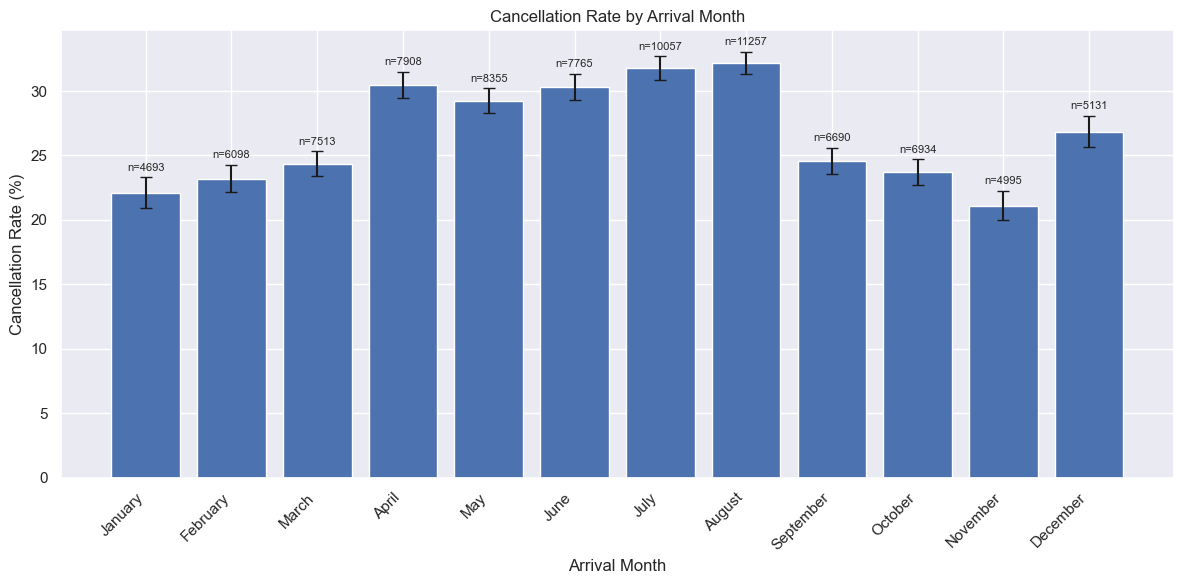

In [52]:
plt.figure(figsize=(12, 6))

x = np.arange(len(month_summary))

rates = month_summary["rate_percent"].values

lower_error = (
    month_summary["rate_percent"]
    - month_summary["ci_low_percent"]
).values

upper_error = (
    month_summary["ci_high_percent"]
    - month_summary["rate_percent"]
).values

plt.bar(
    x,
    rates,
    yerr=[lower_error, upper_error],
    capsize=4
)

plt.xticks(
    x,
    month_summary["ArrivalDateMonth"],
    rotation=45,
    ha="right"
)

plt.ylabel("Cancellation Rate (%)")
plt.xlabel("Arrival Month")
plt.title("Cancellation Rate by Arrival Month")

for i, row in month_summary.iterrows():
    plt.text(
        i,
        row["rate_percent"] + upper_error[i] + 0.5,
        f"n={row['n']}",
        ha="center",
        fontsize=8
    )

plt.tight_layout()

plt.savefig(
    "../outputs/figures/p2_cancellation_rate_by_arrival_month.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

### Interpretation

**Observation:**  
The observed cancellation rate varies across arrival months. It is lowest in November  at approximately 21% and generally increases through the spring and summer, reaching approximately 30% in April and above 31% in July and August. The rate then decreases during September, October, and November, with November having the lowest rate after January at approximately 21%, before increasing again to approximately 27% in December.

**Possible explanation:**  
Differences across arrival months may be associated with seasonal booking patterns, travel periods, or changes in customer behaviour throughout the year.

**Statistical question:**  
Is arrival month statistically associated with cancellation status?

**Important note:**  
The years in the dataset do not contain the same months: 2015 covers July–December, 2016 covers January–December, and 2017 covers January–August. Therefore, monthly patterns should not automatically be interpreted as year-to-year changes.

**Interpretation:**  
The observed differences represent associations between arrival month and cancellation status and do not establish that a particular month causes cancellation.

## 10. Cancellation Rate by Arrival Month and Hotel

**Question:** Does the pattern of cancellation rates across arrival months differ between City Hotel and Resort Hotel?

**Graph:** The line chart compares the observed monthly cancellation rate for City Hotel and Resort Hotel. Each point represents the cancellation rate for that hotel and arrival month.


**Possible explanation:**  
Differences between the hotels may be associated with differences in their customer mix, booking patterns, or the months in which they receive bookings.

**Statistical question:**  
Is the association between arrival month and cancellation status different across the two hotels?

**Important note:**  
The years in the dataset contain different months: 2015 = July–December, 2016 = January–December, and 2017 = January–August. Therefore, monthly differences should not automatically be interpreted as changes from year to year.

**Interpretation:**  
The observed patterns represent associations in the dataset and do not establish that hotel type or arrival month causes cancellation.

In [53]:
hotel_month_summary = (
    df.groupby(
        ["ArrivalDateMonth", "Hotel"],
        observed=True
    )
    .agg(
        cancelled=("IsCanceled", "sum"),
        n=("IsCanceled", "count")
    )
    .reset_index()
)

hotel_month_summary["rate"] = (
    hotel_month_summary["cancelled"]
    / hotel_month_summary["n"]
)

hotel_month_summary["rate_percent"] = (
    hotel_month_summary["rate"] * 100
)

hotel_month_summary

,ArrivalDateMonth,Hotel,cancelled,n,rate,rate_percent
0,January,City Hotel,764,2730,0.279853,27.985348
1,January,Resort Hotel,274,1963,0.139582,13.958227
2,February,City Hotel,975,3605,0.270458,27.045770
3,February,Resort Hotel,440,2493,0.176494,17.649418
4,March,City Hotel,1365,4856,0.281096,28.109555
5,March,Resort Hotel,465,2657,0.175009,17.500941
6,April,City Hotel,1750,5080,0.344488,34.448819
7,April,Resort Hotel,659,2828,0.233027,23.302687
8,May,City Hotel,1746,5413,0.322557,32.255681
9,May,Resort Hotel,696,2942,0.236574,23.657376


In [54]:
ci = hotel_month_summary.apply(
    lambda row: proportion_confint(
        count=row["cancelled"],
        nobs=row["n"],
        alpha=0.05,
        method="wilson"
    ),
    axis=1
)

hotel_month_summary["ci_low"] = [
    x[0] for x in ci
]

hotel_month_summary["ci_high"] = [
    x[1] for x in ci
]

hotel_month_summary["ci_low_percent"] = (
    hotel_month_summary["ci_low"] * 100
)

hotel_month_summary["ci_high_percent"] = (
    hotel_month_summary["ci_high"] * 100
)

hotel_month_summary


,ArrivalDateMonth,Hotel,cancelled,n,rate,rate_percent,ci_low,ci_high,ci_low_percent,ci_high_percent
0,January,City Hotel,764,2730,0.279853,27.985348,0.263332,0.296994,26.333179,29.699384
1,January,Resort Hotel,274,1963,0.139582,13.958227,0.124954,0.155618,12.495447,15.561795
2,February,City Hotel,975,3605,0.270458,27.045770,0.256208,0.285196,25.620762,28.519645
3,February,Resort Hotel,440,2493,0.176494,17.649418,0.162030,0.191954,16.202984,19.195397
4,March,City Hotel,1365,4856,0.281096,28.109555,0.268629,0.293908,26.862878,29.390839
5,March,Resort Hotel,465,2657,0.175009,17.500941,0.161033,0.189924,16.103342,18.992378
6,April,City Hotel,1750,5080,0.344488,34.448819,0.331543,0.357669,33.154257,35.766882
7,April,Resort Hotel,659,2828,0.233027,23.302687,0.217814,0.248964,21.781417,24.896389
8,May,City Hotel,1746,5413,0.322557,32.255681,0.310234,0.335132,31.023358,33.513171
9,May,Resort Hotel,696,2942,0.236574,23.657376,0.221567,0.252268,22.156690,25.226765


In [55]:
hotel_month_summary = (
    hotel_month_summary
    .sort_values(
        ["ArrivalDateMonth", "Hotel"]
    )
    .reset_index(drop=True)
)

hotel_month_summary

,ArrivalDateMonth,Hotel,cancelled,n,rate,rate_percent,ci_low,ci_high,ci_low_percent,ci_high_percent
0,January,City Hotel,764,2730,0.279853,27.985348,0.263332,0.296994,26.333179,29.699384
1,January,Resort Hotel,274,1963,0.139582,13.958227,0.124954,0.155618,12.495447,15.561795
2,February,City Hotel,975,3605,0.270458,27.045770,0.256208,0.285196,25.620762,28.519645
3,February,Resort Hotel,440,2493,0.176494,17.649418,0.162030,0.191954,16.202984,19.195397
4,March,City Hotel,1365,4856,0.281096,28.109555,0.268629,0.293908,26.862878,29.390839
5,March,Resort Hotel,465,2657,0.175009,17.500941,0.161033,0.189924,16.103342,18.992378
6,April,City Hotel,1750,5080,0.344488,34.448819,0.331543,0.357669,33.154257,35.766882
7,April,Resort Hotel,659,2828,0.233027,23.302687,0.217814,0.248964,21.781417,24.896389
8,May,City Hotel,1746,5413,0.322557,32.255681,0.310234,0.335132,31.023358,33.513171
9,May,Resort Hotel,696,2942,0.236574,23.657376,0.221567,0.252268,22.156690,25.226765


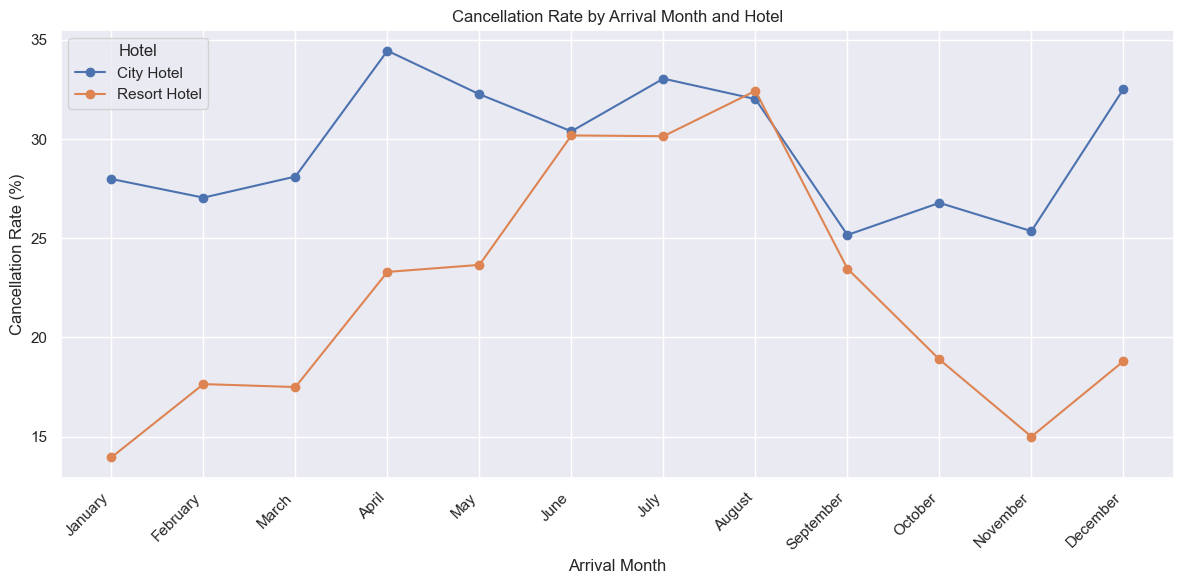

In [56]:
plt.figure(figsize=(12, 6))

for hotel in ["City Hotel", "Resort Hotel"]:
    
    hotel_data = hotel_month_summary[
        hotel_month_summary["Hotel"] == hotel
    ].sort_values("ArrivalDateMonth")
    
    plt.plot(
        hotel_data["ArrivalDateMonth"],
        hotel_data["rate_percent"],
        marker="o",
        label=hotel
    )

plt.ylabel("Cancellation Rate (%)")
plt.xlabel("Arrival Month")
plt.title("Cancellation Rate by Arrival Month and Hotel")

plt.xticks(
    month_order,
    rotation=45,
    ha="right"
)

plt.legend(title="Hotel")

plt.tight_layout()

plt.savefig(
    "../outputs/figures/p2_cancellation_rate_by_month_and_hotel.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

### Interpretation

**Observation:**  
The observed cancellation rate is generally higher for City Hotel than for Resort Hotel across most arrival months. The difference is particularly large from January through May, while the two hotels have more similar cancellation rates during June, July, and August. The rates are nearly equal in August at approximately 32%, after which City Hotel again shows higher cancellation rates from September through December.

**Possible explanation:**  
The differences between hotels may be associated with differences in customer mix, booking patterns, or the types of stays typically made at each hotel across different months.

**Statistical question:**  
Is the association between arrival month and cancellation status different across the two hotels?

**Important note:**  
The years in the dataset contain different months: 2015 covers July–December, 2016 covers January–December, and 2017 covers January–August. Therefore, the monthly patterns should not automatically be interpreted as year-to-year changes.

**Interpretation:**  
The observed differences represent associations between hotel type, arrival month, and cancellation status. They do not establish that hotel type or arrival month causes cancellation.

Part 4 — Numerical EDA
- LeadTime distribution
- LeadTime box plot
- ADR distribution
- ADR box plot
- TotalNights
- Adults / Children / Babies
- Previous cancellation history
- Special requests

## 11. Lead Time Distribution

**Question:** How is booking lead time distributed in the dataset?

**Graph:** The box plot shows the distribution of `LeadTime`, including the median, middle 50% of observations, and potential extreme values.



**Possible explanation:**  
The distribution reflects how far in advance guests make their bookings and may contain a small number of bookings made substantially earlier than most others.

**Statistical question:**  
How dispersed is lead time, and how strongly is it affected by extreme observations?

**Interpretation:**  
The box plot describes the distribution of lead time. It does not establish that any particular lead time causes cancellation.

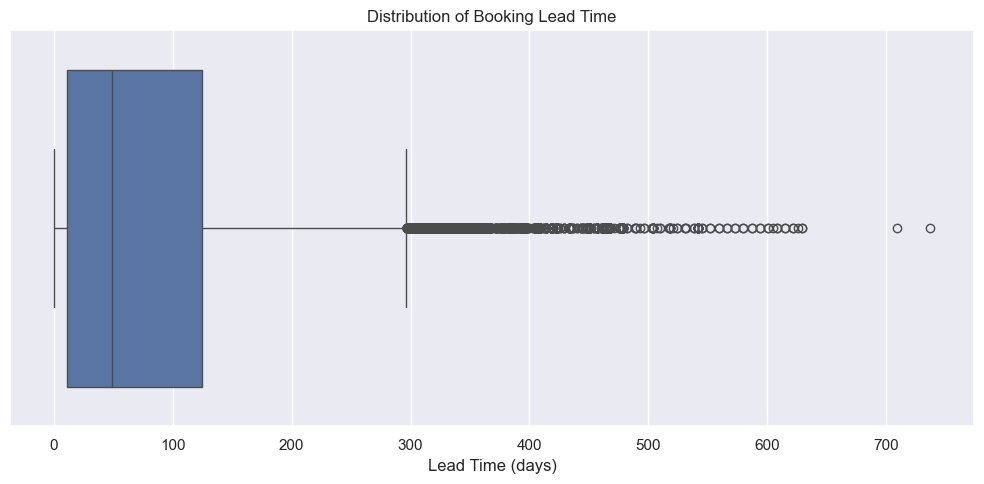

In [57]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df["LeadTime"]
)

plt.xlabel("Lead Time (days)")
plt.title("Distribution of Booking Lead Time")

plt.tight_layout()

plt.savefig(
    "../outputs/figures/p2_lead_time_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

### Interpretation

**Observation:**  
The distribution of booking lead time is strongly right-skewed. The median lead time is 49 days, with the middle 50% of bookings lying between approximately 11 and 125 days. A large number of observations extend beyond the upper whisker, with some bookings having lead times of more than 700 days.

**Possible explanation:**  
Most bookings are made within a relatively moderate period before arrival, while a smaller number of bookings are made substantially further in advance.

**Statistical question:**  
How dispersed is lead time, and how strongly is its distribution affected by unusually large lead-time values?

**Interpretation:**  
The box plot describes the distribution of lead time and highlights its long upper tail. It does not establish that any particular lead time causes cancellation.


## 12. ADR Distribution

**Question:** How is the daily rate (`ADR`) distributed across bookings?

**Graph:** The box plot shows the distribution of ADR. The displayed axis is limited to the typical ADR range so that the extreme value of 5,400 does not compress the main distribution.


**Possible explanation:**  
ADR varies across bookings because different stays may have different room rates, hotel types, or booking characteristics. The extreme value may represent an unusual observation that requires separate consideration.

**Statistical question:**  
How dispersed is ADR, and how strongly is its distribution affected by extreme values?

**Interpretation:**  
The box plot describes the distribution of ADR. Limiting the displayed axis improves readability but does not remove or alter observations in the underlying dataset.

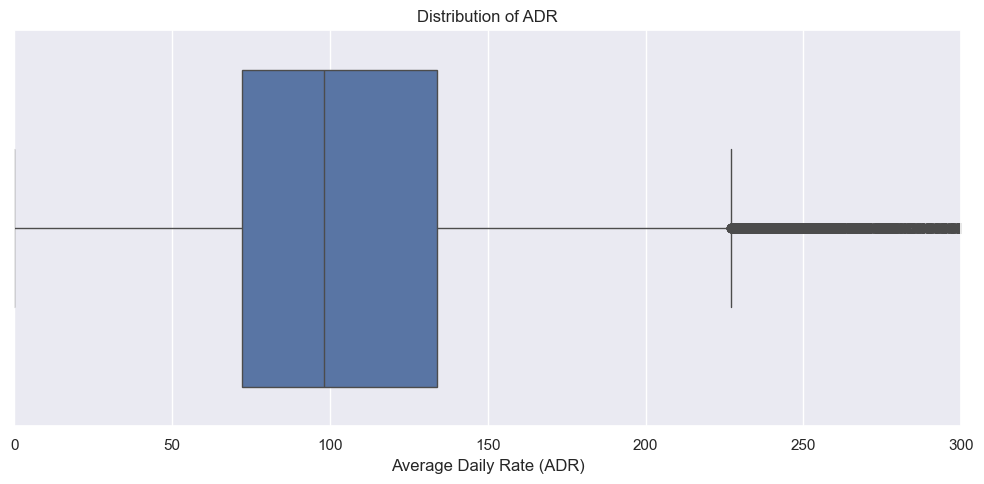

In [58]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=df["ADR"]
)

plt.xlim(0, 300)

plt.xlabel("Average Daily Rate (ADR)")
plt.title("Distribution of ADR")

plt.tight_layout()

plt.savefig(
    "../outputs/figures/p2_adr_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

In [59]:
print("Maximum ADR:", df["ADR"].max())

print(
    "\nADR values above 300:",
    (df["ADR"] > 300).sum()
)

print(
    "\nADR values above 500:",
    (df["ADR"] > 500).sum()
)

Maximum ADR: 5400.0

ADR values above 300: 261

ADR values above 500: 3


### Interpretation

**Observation:**  
The ADR distribution is concentrated around relatively moderate daily rates, with a median of approximately 98 and the middle 50% of observations extending from about 72 to 134. The distribution has a long upper tail, with 261 observations having ADR above 300 and a maximum value of 5,400. The axis is limited to 300 in the visualization so that the main distribution remains readable.

**Possible explanation:**  
Most bookings have ADR values within a moderate range, while a small number have substantially higher rates. These extreme observations may reflect unusual booking or pricing conditions and require separate consideration.

**Statistical question:**  
How dispersed is ADR, and how strongly is its distribution affected by extreme values?

**Interpretation:**  
The box plot describes the distribution of ADR. The displayed axis is limited for readability, but no observations were removed or changed in the underlying dataset.

Part 5 — Room / geographic analysis
- Reserved vs assigned room mismatch
- Top countries
- Cancellation behaviour for top countries

In [60]:
print("Reserved room types:")
print(df["ReservedRoomType"].value_counts())

print("\nAssigned room types:")
print(df["AssignedRoomType"].value_counts())

Reserved room types:
ReservedRoomType
A    56552
D    17398
E     6049
F     2823
G     2052
B      999
C      915
H      596
L        6
P        6
Name: count, dtype: int64

Assigned room types:
AssignedRoomType
A    46313
D    22432
E     7195
F     3627
G     2498
C     2165
B     1820
H      706
I      357
K      276
P        6
L        1
Name: count, dtype: int64


In [61]:
print("\nReserved room types:", df["ReservedRoomType"].nunique())
print("Assigned room types:", df["AssignedRoomType"].nunique())


Reserved room types: 10
Assigned room types: 12


In [62]:
df["RoomMismatch"] = (
    df["ReservedRoomType"] != df["AssignedRoomType"]
)

print(df["RoomMismatch"].value_counts())

RoomMismatch
False    74287
True     13109
Name: count, dtype: int64


In [63]:
room_mismatch_rate = df["RoomMismatch"].mean() * 100

print(
    f"Overall room mismatch rate: {room_mismatch_rate:.2f}%"
)

Overall room mismatch rate: 15.00%


## 13. Room Mismatch

**Question:** Is cancellation behaviour different for bookings where the assigned room type differs from the reserved room type?

**Graph:** The bar chart compares the observed cancellation rate for bookings where the assigned room matches the reserved room and bookings where the two room types differ. The number of bookings (`n`) and 95% confidence intervals are shown.



**Possible explanation:**  
Room assignment differences may be associated with different booking circumstances or customer behaviour.

**Statistical question:**  
Is room mismatch statistically associated with cancellation status?

**Interpretation:**  
The observed relationship represents an association between room mismatch and cancellation status and does not establish that a room mismatch causes cancellation.

In [64]:
room_mismatch_summary = cancellation_rate_summary(
    df,
    "RoomMismatch"
)

room_mismatch_summary

,RoomMismatch,cancelled,n,rate,ci_low,ci_high,rate_percent,ci_low_percent,ci_high_percent
0,False,23408,74287,0.315102,0.311771,0.318452,31.510224,31.177123,31.845237
1,True,617,13109,0.047067,0.043572,0.050827,4.706690,4.357232,5.082686


In [65]:
room_mismatch_summary["RoomMatchStatus"] = (
    room_mismatch_summary["RoomMismatch"]
    .map({
        False: "Room Matched",
        True: "Room Mismatch"
    })
)

room_mismatch_summary

,RoomMismatch,cancelled,n,rate,ci_low,ci_high,rate_percent,ci_low_percent,ci_high_percent,RoomMatchStatus
0,False,23408,74287,0.315102,0.311771,0.318452,31.510224,31.177123,31.845237,Room Matched
1,True,617,13109,0.047067,0.043572,0.050827,4.706690,4.357232,5.082686,Room Mismatch


In [66]:
room_order = [
    "Room Matched",
    "Room Mismatch"
]

room_mismatch_summary["RoomMatchStatus"] = pd.Categorical(
    room_mismatch_summary["RoomMatchStatus"],
    categories=room_order,
    ordered=True
)

room_mismatch_summary = (
    room_mismatch_summary
    .sort_values("RoomMatchStatus")
    .reset_index(drop=True)
)

room_mismatch_summary

,RoomMismatch,cancelled,n,rate,ci_low,ci_high,rate_percent,ci_low_percent,ci_high_percent,RoomMatchStatus
0,False,23408,74287,0.315102,0.311771,0.318452,31.510224,31.177123,31.845237,Room Matched
1,True,617,13109,0.047067,0.043572,0.050827,4.706690,4.357232,5.082686,Room Mismatch


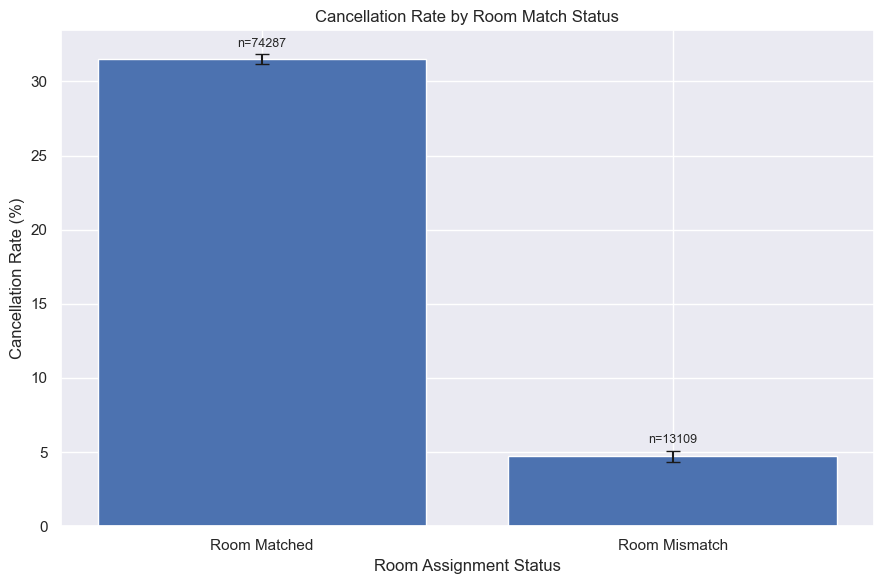

In [67]:
plt.figure(figsize=(9, 6))

x = np.arange(len(room_mismatch_summary))

rates = room_mismatch_summary["rate_percent"].values

lower_error = (
    room_mismatch_summary["rate_percent"]
    - room_mismatch_summary["ci_low_percent"]
).values

upper_error = (
    room_mismatch_summary["ci_high_percent"]
    - room_mismatch_summary["rate_percent"]
).values

plt.bar(
    x,
    rates,
    yerr=[lower_error, upper_error],
    capsize=5
)

plt.xticks(
    x,
    room_mismatch_summary["RoomMatchStatus"]
)

plt.ylabel("Cancellation Rate (%)")
plt.xlabel("Room Assignment Status")
plt.title("Cancellation Rate by Room Match Status")

for i, row in room_mismatch_summary.iterrows():
    plt.text(
        i,
        row["rate_percent"] + upper_error[i] + 0.5,
        f"n={row['n']}",
        ha="center",
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    "../outputs/figures/p2_cancellation_rate_by_room_mismatch.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

### Interpretation

**Observation:**  
Most bookings had matching reserved and assigned room types, with 74,287 bookings compared with 13,109 bookings where the room type differed. The cancellation rate was 31.51% for bookings with a matching room type and 4.71% for bookings with a room mismatch. The 95% confidence intervals are narrow and clearly separated.

**Caution:** A room mismatch may indicate that the assigned room differs from the reserved room, but this does not necessarily imply a negative customer experience because room changes can occur for operational or availability reasons.

**Possible explanation:**  
The difference in cancellation rates may be associated with differences in booking circumstances or customer characteristics between bookings with matching and mismatched room assignments.

**Statistical question:**  
Is room assignment mismatch statistically associated with cancellation status?

**Interpretation:**  
There is a strong observed association between room match status and cancellation rate in this dataset. This association does not establish that room matching or mismatch causes cancellation.

## 14. Top Countries

**Question:** Which countries account for the largest number of bookings, and how does cancellation rate vary among these countries?

**Graph:** The chart compares cancellation rates for the countries with the largest numbers of bookings. The number of bookings (`n`) and 95% confidence intervals are shown.



**Possible explanation:**  
Differences in cancellation rates across countries may be associated with differences in customer mix, booking channels, travel patterns, or other characteristics of the bookings.

**Statistical question:**  
Is country of origin statistically associated with cancellation status among the countries shown?

**Interpretation:**  
The chart shows an association between country and cancellation status. It does not establish that a customer's country causes a booking to be cancelled.

In [68]:
print("Number of unique countries:", df["Country"].nunique())

print("\nTop 20 countries by number of bookings:")
print(df["Country"].value_counts().head(20))

Number of unique countries: 178

Top 20 countries by number of bookings:
Country
PRT    27453
GBR    10433
FRA     8837
ESP     7252
DEU     5387
ITA     3066
IRL     3016
BEL     2081
BRA     1995
NLD     1911
USA     1875
CHE     1570
CN      1093
AUT      947
SWE      837
CHN      816
POL      765
RUS      561
NOR      515
ROU      458
Name: count, dtype: int64


In [69]:
print("\nMissing country values:", df["Country"].isna().sum())


Missing country values: 0


In [70]:
top_countries = (
    df["Country"]
    .value_counts()
    .head(10)
)

top_countries

Country
PRT    27453
GBR    10433
FRA     8837
ESP     7252
DEU     5387
ITA     3066
IRL     3016
BEL     2081
BRA     1995
NLD     1911
Name: count, dtype: int64

In [71]:
top_country_list = top_countries.index.tolist()

df_top_countries = df[
    df["Country"].isin(top_country_list)
].copy()

print(
    "Rows in top-country dataset:",
    len(df_top_countries)
)

Rows in top-country dataset: 71431


In [72]:
country_summary = cancellation_rate_summary(
    df_top_countries,
    "Country"
)

country_summary

,Country,cancelled,n,rate,ci_low,ci_high,rate_percent,ci_low_percent,ci_high_percent
0,BEL,411,2081,0.197501,0.180960,0.215157,19.750120,18.096041,21.515674
1,BRA,727,1995,0.364411,0.343572,0.385771,36.441103,34.357192,38.577129
2,DEU,1053,5387,0.195471,0.185099,0.206276,19.547058,18.509937,20.627580
3,ESP,1862,7252,0.256757,0.246833,0.266938,25.675676,24.683322,26.693786
4,FRA,1733,8837,0.196107,0.187962,0.204517,19.610728,18.796176,20.451688
5,GBR,1985,10433,0.190262,0.182845,0.197907,19.026167,18.284452,19.790682
6,IRL,668,3016,0.221485,0.207025,0.236654,22.148541,20.702523,23.665417
7,ITA,1075,3066,0.350620,0.333926,0.367687,35.061970,33.392616,36.768709
8,NLD,350,1911,0.183150,0.166450,0.201122,18.315018,16.644984,20.112182
9,PRT,9791,27453,0.356646,0.351000,0.362332,35.664590,35.100006,36.233186


In [73]:
country_order = top_countries.index.tolist()

country_summary["Country"] = pd.Categorical(
    country_summary["Country"],
    categories=country_order,
    ordered=True
)

country_summary = (
    country_summary
    .sort_values("Country")
    .reset_index(drop=True)
)

country_summary

,Country,cancelled,n,rate,ci_low,ci_high,rate_percent,ci_low_percent,ci_high_percent
0,PRT,9791,27453,0.356646,0.351000,0.362332,35.664590,35.100006,36.233186
1,GBR,1985,10433,0.190262,0.182845,0.197907,19.026167,18.284452,19.790682
2,FRA,1733,8837,0.196107,0.187962,0.204517,19.610728,18.796176,20.451688
3,ESP,1862,7252,0.256757,0.246833,0.266938,25.675676,24.683322,26.693786
4,DEU,1053,5387,0.195471,0.185099,0.206276,19.547058,18.509937,20.627580
5,ITA,1075,3066,0.350620,0.333926,0.367687,35.061970,33.392616,36.768709
6,IRL,668,3016,0.221485,0.207025,0.236654,22.148541,20.702523,23.665417
7,BEL,411,2081,0.197501,0.180960,0.215157,19.750120,18.096041,21.515674
8,BRA,727,1995,0.364411,0.343572,0.385771,36.441103,34.357192,38.577129
9,NLD,350,1911,0.183150,0.166450,0.201122,18.315018,16.644984,20.112182


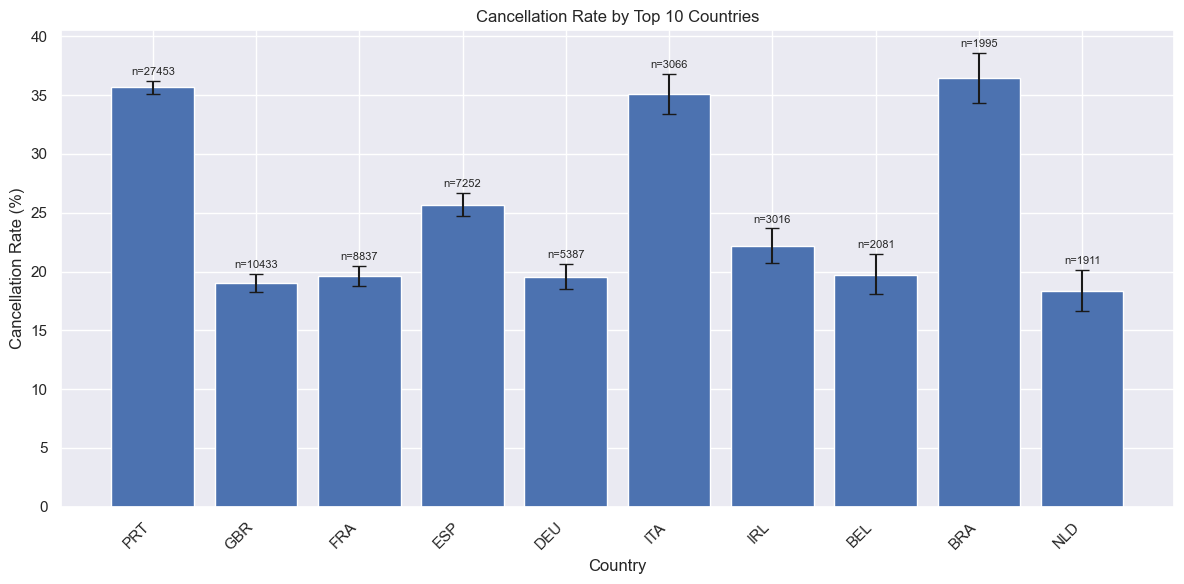

In [74]:
plt.figure(figsize=(12, 6))

x = np.arange(len(country_summary))

rates = country_summary["rate_percent"].values

lower_error = (
    country_summary["rate_percent"]
    - country_summary["ci_low_percent"]
).values

upper_error = (
    country_summary["ci_high_percent"]
    - country_summary["rate_percent"]
).values

plt.bar(
    x,
    rates,
    yerr=[lower_error, upper_error],
    capsize=5
)

plt.xticks(
    x,
    country_summary["Country"],
    rotation=45,
    ha="right"
)

plt.ylabel("Cancellation Rate (%)")
plt.xlabel("Country")
plt.title("Cancellation Rate by Top 10 Countries")

for i, row in country_summary.iterrows():
    plt.text(
        i,
        row["rate_percent"] + upper_error[i] + 0.5,
        f"n={row['n']}",
        ha="center",
        fontsize=8
    )

plt.tight_layout()

plt.savefig(
    "../outputs/figures/p2_cancellation_rate_top_countries.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

### Interpretation

**Observation:**  
Cancellation rates vary across the ten countries with the largest numbers of bookings. PRT has the largest booking count (`n=27,453`) and a cancellation rate of approximately 35.7%. BRA and ITA also show relatively high cancellation rates, while GBR, FRA, DEU, BEL, and NLD have lower rates of approximately 18–20%.

**Possible explanation:**  
Differences in cancellation rates across countries may be associated with differences in customer mix, booking channels, travel patterns, or other characteristics of the bookings.

**Statistical question:**  
Is country of origin statistically associated with cancellation status among the countries shown?

**Interpretation:**  
The chart shows an association between country and cancellation status among the top ten countries by booking volume. It does not establish that a customer's country causes a booking to be cancelled.

## 15. Bayes Theorem: Online TA and Cancellation

**Question:** How does knowing that a booking was made through Online TA affect the probability of cancellation?

**Approach:** We calculate the overall cancellation probability, the probability of cancellation given Online TA, and the corresponding probabilities for bookings that were not made through Online TA. Bayes' theorem is then used to compare the prior and posterior probabilities.

**Observation:**  
The probability of cancellation given Online TA is approximately 0.3535 (35.35%), which differs from the overall cancellation probability.

**Possible explanation:**  
The difference may reflect differences in the characteristics of bookings made through Online TA compared with other distribution channels.

**Statistical question:**  
Is the observed relationship between Online TA booking status and cancellation status statistically meaningful?

**Interpretation:**  
The calculations describe an association between distribution channel and cancellation status. They do not establish that using Online TA causes a booking to be cancelled.

In [75]:
print(df["MarketSegment"].value_counts())

MarketSegment
Online TA        51618
Offline TA/TO    13889
Direct           11804
Groups            4942
Corporate         4212
Complementary      702
Aviation           227
Undefined            2
Name: count, dtype: int64


In [78]:
total_bookings = len(df)

cancelled_bookings = df["IsCanceled"].sum()

online_ta_bookings = (
    df["MarketSegment"] == "Online TA"
).sum()

online_ta_cancelled = (
    (df["MarketSegment"] == "Online TA")
    & (df["IsCanceled"] == 1)
).sum()

print("Total bookings:", total_bookings)
print("Cancelled bookings:", cancelled_bookings)
print("Online TA bookings:", online_ta_bookings)
print("Online TA cancelled:", online_ta_cancelled)

Total bookings: 87396
Cancelled bookings: 24025
Online TA bookings: 51618
Online TA cancelled: 18245


In [79]:
p_cancelled = cancelled_bookings / total_bookings

p_online_ta = online_ta_bookings / total_bookings

p_cancelled_given_online_ta = (
    online_ta_cancelled / online_ta_bookings
)

print(f"P(Cancelled) = {p_cancelled:.4f}")
print(f"P(Online TA) = {p_online_ta:.4f}")
print(
    f"P(Cancelled | Online TA) = "
    f"{p_cancelled_given_online_ta:.4f}"
)

P(Cancelled) = 0.2749
P(Online TA) = 0.5906
P(Cancelled | Online TA) = 0.3535


total probability check

In [80]:
p_not_online_ta = 1 - p_online_ta

not_online_ta_bookings = (
    df["MarketSegment"] != "Online TA"
).sum()

not_online_ta_cancelled = (
    (df["MarketSegment"] != "Online TA")
    & (df["IsCanceled"] == 1)
).sum()

p_cancelled_given_not_online_ta = (
    not_online_ta_cancelled / not_online_ta_bookings
)

print(
    f"P(not Online TA) = {p_not_online_ta:.4f}"
)

print(
    f"P(Cancelled | not Online TA) = "
    f"{p_cancelled_given_not_online_ta:.4f}"
)

P(not Online TA) = 0.4094
P(Cancelled | not Online TA) = 0.1616


In [81]:
total_probability_check = (
    p_cancelled_given_online_ta * p_online_ta
    +
    p_cancelled_given_not_online_ta * p_not_online_ta
)

print(
    f"Total probability check = "
    f"{total_probability_check:.4f}"
)

print(
    f"Actual P(Cancelled) = "
    f"{p_cancelled:.4f}"
)

print(
    f"Difference = "
    f"{abs(total_probability_check - p_cancelled):.10f}"
)

Total probability check = 0.2749
Actual P(Cancelled) = 0.2749
Difference = 0.0000000000


Bayes Posterior

In [82]:
p_online_ta_given_cancelled = (
    p_cancelled_given_online_ta
    * p_online_ta
    / p_cancelled
)

print(
    f"P(Online TA | Cancelled) = "
    f"{p_online_ta_given_cancelled:.4f}"
)

P(Online TA | Cancelled) = 0.7594


Prior vs Posterior Table

In [83]:
bayes_table = pd.DataFrame({
    "Probability": [
        p_online_ta,
        p_online_ta_given_cancelled
    ],
    "Percentage": [
        p_online_ta * 100,
        p_online_ta_given_cancelled * 100
    ]
}, index=[
    "Prior: P(Online TA)",
    "Posterior: P(Online TA | Cancelled)"
])

bayes_table

,Probability,Percentage
Prior: P(Online TA),0.590622,59.062200
Posterior: P(Online TA | Cancelled),0.759417,75.941727


### Interpretation

**Observation:**  
The probability of cancellation given an Online TA booking is 0.3535 (35.35%), compared with an overall cancellation probability of 0.2749 (27.49%). The Bayes calculation compares the probability of Online TA before and after conditioning on cancellation.

**Possible explanation:**  
The difference between the prior and posterior probabilities may reflect differences in the market signsld among cancelled bookings.

**Statistical question:**  
How much does observing a cancellation change the probability that the booking came through Online TA?

**Interpretation:**  
Bayes' theorem updates the probability of Online TA based on the observed cancellation status. This represents a probabilistic association and does not establish that Online TA causes cancellation.

Bayes Visualization

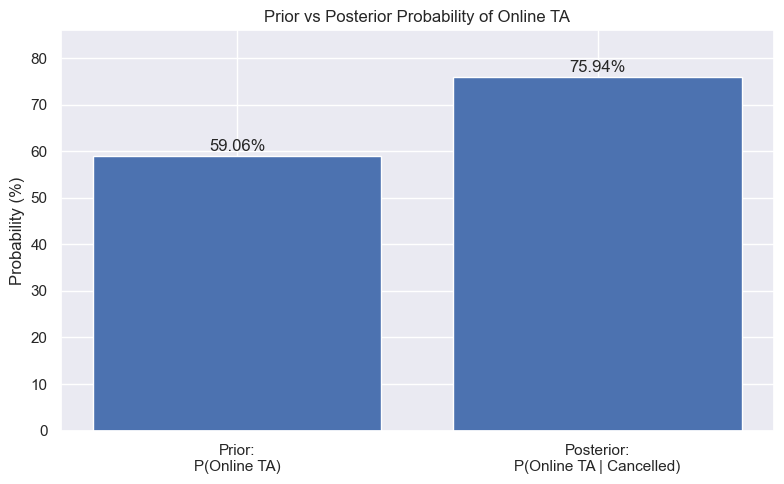

In [84]:
plt.figure(figsize=(8, 5))

labels = [
    "Prior:\nP(Online TA)",
    "Posterior:\nP(Online TA | Cancelled)"
]

values = [
    p_online_ta * 100,
    p_online_ta_given_cancelled * 100
]

bars = plt.bar(labels, values)

plt.ylabel("Probability (%)")
plt.title("Prior vs Posterior Probability of Online TA")

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.ylim(0, max(values) + 10)

plt.tight_layout()

plt.savefig(
    "../outputs/figures/p2_bayes_prior_vs_posterior.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

Observation: The probability of Online TA increases from 59.06% before observing cancellation to 75.94% among cancelled bookings.
Interpretation: This shows that Online TA is more prevalent among cancelled bookings. The result represents an association and does not establish that Online TA causes cancellation.

### Year and Month Coverage Note

The dataset covers different sets of arrival months across the three years: **2015 contains July–December, 2016 contains January–December, and 2017 contains January–August**. Therefore, monthly cancellation rates should be interpreted with this unequal year coverage in mind, since some months are represented in fewer years than others.

### C2.1 — Bernoulli Random Variable

We define a Bernoulli random variable \(X\) for a randomly selected hotel booking, where \(X=1\) if the booking is cancelled and \(X=0\) otherwise. The probability of cancellation is estimated from the cleaned dataset as \(p=0.2749\), while the probability of no cancellation is \(1-p=0.7251\).

In [85]:
# Bernoulli random variable based on the observed cancellation rate

p_cancel = p_cancelled
p_not_cancel = 1 - p_cancel

print("Bernoulli random variable:")
print("X = 1 -> Cancelled")
print("X = 0 -> Not Cancelled")
print()
print(f"P(X = 1) = {p_cancel:.4f}")
print(f"P(X = 0) = {p_not_cancel:.4f}")
print(f"Check: P(X=1) + P(X=0) = {p_cancel + p_not_cancel:.4f}")

Bernoulli random variable:
X = 1 -> Cancelled
X = 0 -> Not Cancelled

P(X = 1) = 0.2749
P(X = 0) = 0.7251
Check: P(X=1) + P(X=0) = 1.0000


bernoulli probability distribution


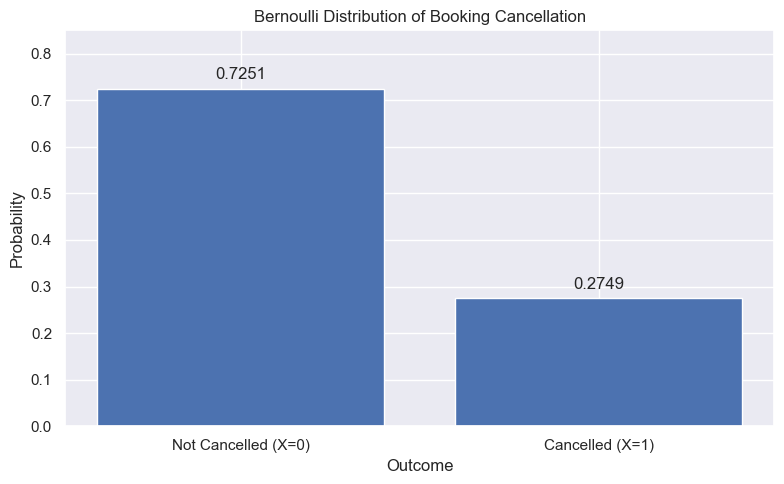

In [86]:
bernoulli_labels = ["Not Cancelled (X=0)", "Cancelled (X=1)"]
bernoulli_probs = [p_not_cancel, p_cancel]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    bernoulli_labels,
    bernoulli_probs
)

plt.ylabel("Probability")
plt.xlabel("Outcome")
plt.title("Bernoulli Distribution of Booking Cancellation")

for bar, value in zip(bars, bernoulli_probs):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{value:.4f}",
        ha="center"
    )

plt.ylim(0, 0.85)
plt.tight_layout()

plt.savefig(
    "../outputs/figures/p2_bernoulli_cancellation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

**Question:** What are the two possible outcomes for a randomly selected booking?

**Graph:** The chart shows the probabilities of cancellation and non-cancellation for one booking.

**Observation:** A randomly selected booking has an estimated 27.49% probability of being cancelled and a 72.51% probability of not being cancelled.

**Possible explanation:** These probabilities describe the observed cancellation pattern in the cleaned dataset; they do not imply that any particular booking will be cancelled.

**Statistical question:** Is the observed cancellation probability different across different booking characteristics?

### C2.2 — Binomial Random Variable

We extend the Bernoulli experiment to a group of 10 bookings and let \(Y\) represent the number of cancelled bookings. Using the observed cancellation probability \(p=0.2749\), we model \(Y\) as a Binomial random variable with \(n=10\) trials and \(p=0.2749\). This assumes the individual booking outcomes are treated as independent and have the same cancellation probability.

In [87]:
n = 10
p = p_cancel

# Probability of exactly 3 cancellations
prob_exactly_3 = binom.pmf(3, n, p)

# Probability of no cancellations
prob_zero = binom.pmf(0, n, p)

# Probability of at least 1 cancellation
prob_at_least_1 = 1 - binom.pmf(0, n, p)

# Probability of at most 3 cancellations
prob_at_most_3 = binom.cdf(3, n, p)

print(f"Number of bookings (n): {n}")
print(f"Cancellation probability (p): {p:.4f}")
print()
print(f"P(Y = 3) = {prob_exactly_3:.4f}")
print(f"P(Y = 0) = {prob_zero:.4f}")
print(f"P(Y >= 1) = {prob_at_least_1:.4f}")
print(f"P(Y <= 3) = {prob_at_most_3:.4f}")

Number of bookings (n): 10
Cancellation probability (p): 0.2749

P(Y = 3) = 0.2627
P(Y = 0) = 0.0402
P(Y >= 1) = 0.9598
P(Y <= 3) = 0.7151


expected number of cancellations


In [88]:
expected_cancellations = n * p
variance_cancellations = n * p * (1 - p)

print(f"Expected number of cancellations = {expected_cancellations:.4f}")
print(f"Variance = {variance_cancellations:.4f}")

Expected number of cancellations = 2.7490
Variance = 1.9933


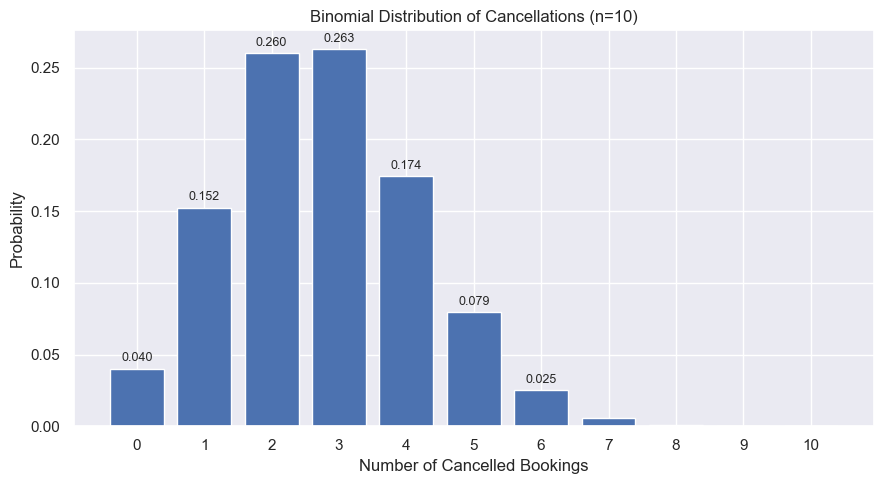

In [89]:
x = np.arange(0, n + 1)
probabilities = binom.pmf(x, n, p)

plt.figure(figsize=(9, 5))

bars = plt.bar(x, probabilities)

plt.xlabel("Number of Cancelled Bookings")
plt.ylabel("Probability")
plt.title("Binomial Distribution of Cancellations (n=10)")

for bar, value in zip(bars, probabilities):
    if value > 0.01:
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.005,
            f"{value:.3f}",
            ha="center",
            fontsize=9
        )

plt.xticks(x)
plt.tight_layout()

plt.savefig(
    "../outputs/figures/p2_binomial_cancellation_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

**Question:** If 10 bookings are considered, how many cancellations are most likely under the observed cancellation probability?

**Graph:** The Binomial distribution shows the probability of obtaining 0 through 10 cancelled bookings among 10 bookings.

**Observation:** The probabilities are concentrated around the middle of the distribution, with the expected number of cancellations being approximately 2.75 out of 10.

**Possible explanation:** The shape of the distribution follows from the observed cancellation probability of 27.49% and the assumption that the bookings are independent trials with the same probability.

**Statistical question:** Does the observed number of cancellations in groups of bookings agree with the distribution expected from the overall cancellation probability?

In [90]:
binomial_table = pd.DataFrame({
    "Cancelled Bookings": x,
    "Probability": probabilities,
    "Percentage": probabilities * 100
})

binomial_table

,Cancelled Bookings,Probability,Percentage
0,0,0.040178,4.017816
1,1,0.152322,15.232209
2,2,0.259865,25.986526
3,3,0.262718,26.271798
4,4,0.174301,17.430132
5,5,0.079297,7.929664
6,6,0.025052,2.505223
7,7,0.005427,0.542727
8,8,0.000772,0.077159
9,9,0.000065,0.006500


### Binomial Example — 100 Bookings

Suppose the probability that a booking is cancelled is estimated as **30%**. If we randomly select **100 bookings**, let \(X\) represent the number of cancelled bookings.

Then:

\[
X \sim Binomial(n=100,\ p=0.30)
\]

The expected number of cancellations is:

\[
E[X] = np = 100(0.30) = 30
\]

The standard deviation is:

\[
\sigma = \sqrt{np(1-p)}
= \sqrt{100(0.30)(0.70)}
\approx 4.58
\]

Therefore, among 100 bookings, we would expect approximately **30 cancellations**, with a standard deviation of about **4.58**.

In [119]:
from scipy.stats import binom

n = 100
p = 0.30

expected = n * p
std_dev = (n * p * (1 - p)) ** 0.5

print("Expected cancellations:", expected)
print("Standard deviation:", round(std_dev, 2))

Expected cancellations: 30.0
Standard deviation: 4.58


### B2 — Cancellation by Hotel within Market Segment

The overall cancellation rate differs between City Hotel and Resort Hotel, but hotel type is also related to the distribution of bookings across market segments. To examine this more closely, cancellation rates are compared between hotels within each market segment. This helps show whether the hotel-level difference remains when bookings are considered within the same market segment.

In [91]:
# Cancellation rate by Hotel within each Market Segment

b2_summary = (
    df.groupby(["MarketSegment", "Hotel"])
    .agg(
        cancelled=("IsCanceled", "sum"),
        n=("IsCanceled", "count")
    )
    .reset_index()
)

b2_summary["rate"] = (
    b2_summary["cancelled"] / b2_summary["n"]
)

b2_summary["rate_percent"] = (
    b2_summary["rate"] * 100
)

b2_summary

,MarketSegment,Hotel,cancelled,n,rate,rate_percent
0,Aviation,City Hotel,45,227,0.198238,19.823789
1,Complementary,City Hotel,57,513,0.111111,11.111111
2,Complementary,Resort Hotel,31,189,0.164021,16.402116
3,Corporate,City Hotel,264,2227,0.118545,11.854513
4,Corporate,Resort Hotel,246,1985,0.123929,12.392947
5,Direct,City Hotel,912,5559,0.164058,16.405828
6,Direct,Resort Hotel,825,6245,0.132106,13.210568
7,Groups,City Hotel,890,2635,0.337761,33.776091
8,Groups,Resort Hotel,445,2307,0.192891,19.289120
9,Offline TA/TO,City Hotel,1261,7271,0.173429,17.342869


Add 95% confidence intervals

In [92]:
# Calculate 95% Wilson confidence intervals

ci_values = b2_summary.apply(
    lambda row: proportion_confint(
        row["cancelled"],
        row["n"],
        alpha=0.05,
        method="wilson"
    ),
    axis=1
)

b2_summary["ci_low"] = [
    value[0] for value in ci_values
]

b2_summary["ci_high"] = [
    value[1] for value in ci_values
]

b2_summary["ci_low_percent"] = (
    b2_summary["ci_low"] * 100
)

b2_summary["ci_high_percent"] = (
    b2_summary["ci_high"] * 100
)

b2_summary

,MarketSegment,Hotel,cancelled,n,rate,rate_percent,ci_low,ci_high,ci_low_percent,ci_high_percent
0,Aviation,City Hotel,45,227,0.198238,19.823789,0.151586,0.254933,15.158606,25.493303
1,Complementary,City Hotel,57,513,0.111111,11.111111,0.086754,0.141249,8.675389,14.124922
2,Complementary,Resort Hotel,31,189,0.164021,16.402116,0.118024,0.223404,11.802403,22.340389
3,Corporate,City Hotel,264,2227,0.118545,11.854513,0.105772,0.132632,10.577199,13.263198
4,Corporate,Resort Hotel,246,1985,0.123929,12.392947,0.110156,0.139155,11.015644,13.915527
5,Direct,City Hotel,912,5559,0.164058,16.405828,0.154556,0.174025,15.455585,17.402469
6,Direct,Resort Hotel,825,6245,0.132106,13.210568,0.123933,0.140730,12.393338,14.073031
7,Groups,City Hotel,890,2635,0.337761,33.776091,0.319951,0.356043,31.995068,35.604349
8,Groups,Resort Hotel,445,2307,0.192891,19.289120,0.177306,0.209497,17.730625,20.949720
9,Offline TA/TO,City Hotel,1261,7271,0.173429,17.342869,0.164899,0.182303,16.489907,18.230320


In [93]:
b2_summary[
    [
        "MarketSegment",
        "Hotel",
        "n",
        "cancelled",
        "rate_percent",
        "ci_low_percent",
        "ci_high_percent"
    ]
]

,MarketSegment,Hotel,n,cancelled,rate_percent,ci_low_percent,ci_high_percent
0,Aviation,City Hotel,227,45,19.823789,15.158606,25.493303
1,Complementary,City Hotel,513,57,11.111111,8.675389,14.124922
2,Complementary,Resort Hotel,189,31,16.402116,11.802403,22.340389
3,Corporate,City Hotel,2227,264,11.854513,10.577199,13.263198
4,Corporate,Resort Hotel,1985,246,12.392947,11.015644,13.915527
5,Direct,City Hotel,5559,912,16.405828,15.455585,17.402469
6,Direct,Resort Hotel,6245,825,13.210568,12.393338,14.073031
7,Groups,City Hotel,2635,890,33.776091,31.995068,35.604349
8,Groups,Resort Hotel,2307,445,19.289120,17.730625,20.949720
9,Offline TA/TO,City Hotel,7271,1261,17.342869,16.489907,18.230320


In [94]:
b2_plot = b2_summary[
    b2_summary["MarketSegment"] != "Undefined"
].copy()

print("Market segments included:")
print(b2_plot["MarketSegment"].unique())

print("\nNumber of rows:", len(b2_plot))

Market segments included:
<StringArray>
[     'Aviation', 'Complementary',     'Corporate',        'Direct',
        'Groups', 'Offline TA/TO',     'Online TA']
Length: 7, dtype: str

Number of rows: 13


In [95]:
market_order = [
    "Online TA",
    "Offline TA/TO",
    "Direct",
    "Groups",
    "Corporate",
    "Complementary",
    "Aviation"
]

b2_plot["MarketSegment"] = pd.Categorical(
    b2_plot["MarketSegment"],
    categories=market_order,
    ordered=True
)

b2_plot = b2_plot.sort_values(
    ["MarketSegment", "Hotel"]
)

b2_plot

,MarketSegment,Hotel,cancelled,n,rate,rate_percent,ci_low,ci_high,ci_low_percent,ci_high_percent
11,Online TA,City Hotel,12618,34994,0.360576,36.057610,0.355561,0.365622,35.556077,36.562203
12,Online TA,Resort Hotel,5627,16624,0.338487,33.848653,0.331331,0.345716,33.133140,34.571628
9,Offline TA/TO,City Hotel,1261,7271,0.173429,17.342869,0.164899,0.182303,16.489907,18.230320
10,Offline TA/TO,Resort Hotel,802,6618,0.121185,12.118465,0.113541,0.129268,11.354118,12.926764
5,Direct,City Hotel,912,5559,0.164058,16.405828,0.154556,0.174025,15.455585,17.402469
6,Direct,Resort Hotel,825,6245,0.132106,13.210568,0.123933,0.140730,12.393338,14.073031
7,Groups,City Hotel,890,2635,0.337761,33.776091,0.319951,0.356043,31.995068,35.604349
8,Groups,Resort Hotel,445,2307,0.192891,19.289120,0.177306,0.209497,17.730625,20.949720
3,Corporate,City Hotel,264,2227,0.118545,11.854513,0.105772,0.132632,10.577199,13.263198
4,Corporate,Resort Hotel,246,1985,0.123929,12.392947,0.110156,0.139155,11.015644,13.915527


confounding chart

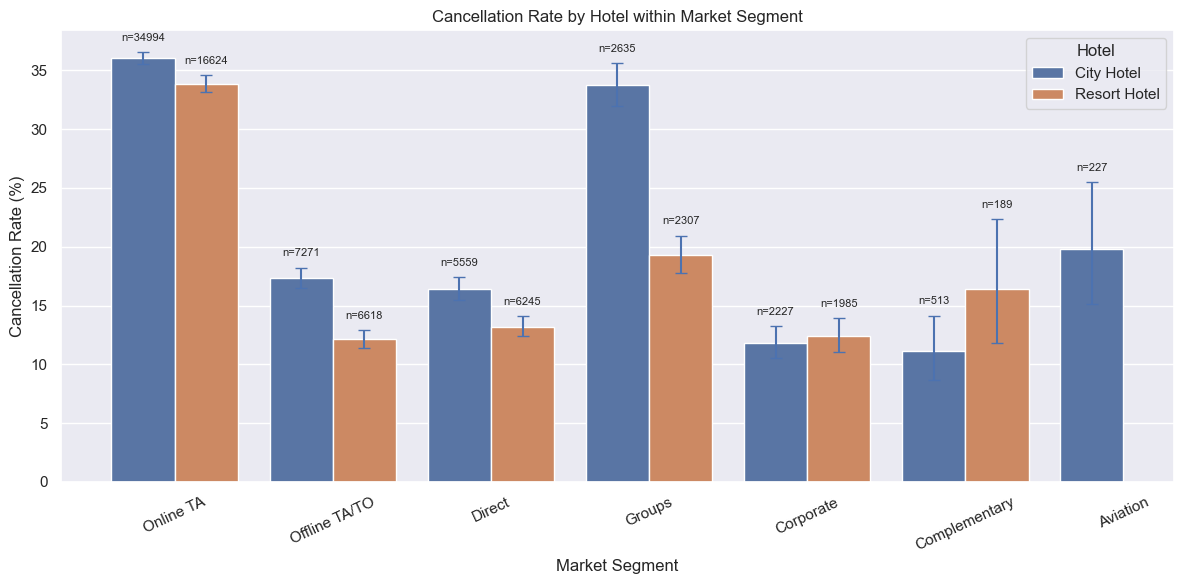

In [96]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=b2_plot,
    x="MarketSegment",
    y="rate_percent",
    hue="Hotel",
    errorbar=None
)

# Add 95% CI error bars and n labels
hotels = ["City Hotel", "Resort Hotel"]

for i, segment in enumerate(market_order):
    segment_data = b2_plot[
        b2_plot["MarketSegment"] == segment
    ]

    for j, hotel in enumerate(hotels):

        row = segment_data[
            segment_data["Hotel"] == hotel
        ]

        if len(row) == 0:
            continue

        row = row.iloc[0]

        # Position based on the grouped bars
        container = ax.containers[j]

        if i >= len(container):
            continue

        bar = container[i]

        x_pos = (
            bar.get_x() +
            bar.get_width() / 2
        )

        y = row["rate_percent"]

        lower_error = (
            y - row["ci_low_percent"]
        )

        upper_error = (
            row["ci_high_percent"] - y
        )

        ax.errorbar(
            x_pos,
            y,
            yerr=[
                [lower_error],
                [upper_error]
            ],
            fmt="none",
            capsize=4
        )

        ax.text(
            x_pos,
            row["ci_high_percent"] + 0.8,
            f'n={int(row["n"])}',
            ha="center",
            va="bottom",
            fontsize=8
        )

plt.xlabel("Market Segment")
plt.ylabel("Cancellation Rate (%)")
plt.title(
    "Cancellation Rate by Hotel within Market Segment"
)

plt.xticks(rotation=25)
plt.legend(title="Hotel")

plt.tight_layout()

plt.savefig(
    "../outputs/figures/p2_cancellation_hotel_within_market_segment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

Cancellation rates vary by both hotel type and market segment. City Hotel generally has higher cancellation rates than Resort Hotel for Online TA, Groups, Offline TA/TO, and Direct bookings, with the largest difference observed for Groups. However, Corporate bookings show very similar cancellation rates between the two hotels, while Complementary bookings have a higher cancellation rate for Resort Hotel. This indicates that the relationship between hotel type and cancellation behavior depends on the market segment.

**Question:** Is the difference in cancellation rates between City Hotel and Resort Hotel similar within each market segment?

**Graph:** The chart compares City Hotel and Resort Hotel cancellation rates separately within each market segment, with 95% confidence intervals and the number of bookings shown for each group.

**Observation:** The hotel-level cancellation difference can be compared within the same market segment rather than only using the overall hotel rates.

**Possible explanation:** Differences between hotels may be partly linked to the different market-segment composition of their bookings. Within-segment comparisons provide a clearer view of the hotel difference.

**Statistical question:** After accounting for market segment, is hotel type still associated with differences in cancellation rates?

In [97]:
b2_pivot = b2_plot.pivot(
    index="MarketSegment",
    columns="Hotel",
    values="rate_percent"
)

b2_pivot

Hotel,City Hotel,Resort Hotel
MarketSegment,,
Online TA,36.057610,33.848653
Offline TA/TO,17.342869,12.118465
Direct,16.405828,13.210568
Groups,33.776091,19.289120
Corporate,11.854513,12.392947
Complementary,11.111111,16.402116
Aviation,19.823789,NaN


## B3. Cancellation Rate by Year Using Comparable Months

To compare cancellation rates across years fairly, only July and August are used because these months are present in 2015, 2016, and 2017. This avoids differences caused by the unequal month coverage across years.

In [98]:
year_comparison_df = df[
    df["ArrivalDateMonth"].isin(["July", "August"])
].copy()

print("Years included:")
print(sorted(year_comparison_df["ArrivalDateYear"].unique()))

print("\nMonths included:")
print(year_comparison_df["ArrivalDateMonth"].unique())

print("\nNumber of bookings:")
print(len(year_comparison_df))

Years included:
[np.int64(2015), np.int64(2016), np.int64(2017)]

Months included:
['July', 'August']
Categories (12, str): ['January' < 'February' < 'March' < 'April' ... 'September' < 'October' < 'November' < 'December']

Number of bookings:
21314


calculate cancellation rate

In [99]:
b3_summary = (
    year_comparison_df
    .groupby("ArrivalDateYear")
    .agg(
        n=("IsCanceled", "size"),
        cancelled=("IsCanceled", "sum")
    )
    .reset_index()
)

b3_summary["rate"] = (
    b3_summary["cancelled"] / b3_summary["n"]
)

b3_summary["rate_percent"] = (
    b3_summary["rate"] * 100
)

b3_summary

,ArrivalDateYear,n,cancelled,rate,rate_percent
0,2015,4127,1083,0.262418,26.241822
1,2016,8274,2532,0.306019,30.601885
2,2017,8913,3206,0.359699,35.969932


Add 95% confidence intervals

In [100]:
b3_summary["ci_low"], b3_summary["ci_high"] = proportion_confint(
    b3_summary["cancelled"],
    b3_summary["n"],
    alpha=0.05,
    method="wilson"
)

b3_summary["ci_low_percent"] = b3_summary["ci_low"] * 100
b3_summary["ci_high_percent"] = b3_summary["ci_high"] * 100

b3_summary

,ArrivalDateYear,n,cancelled,rate,rate_percent,ci_low,ci_high,ci_low_percent,ci_high_percent
0,2015,4127,1083,0.262418,26.241822,0.249221,0.276057,24.922110,27.605722
1,2016,8274,2532,0.306019,30.601885,0.296181,0.316037,29.618102,31.603673
2,2017,8913,3206,0.359699,35.969932,0.349799,0.369721,34.979854,36.972097


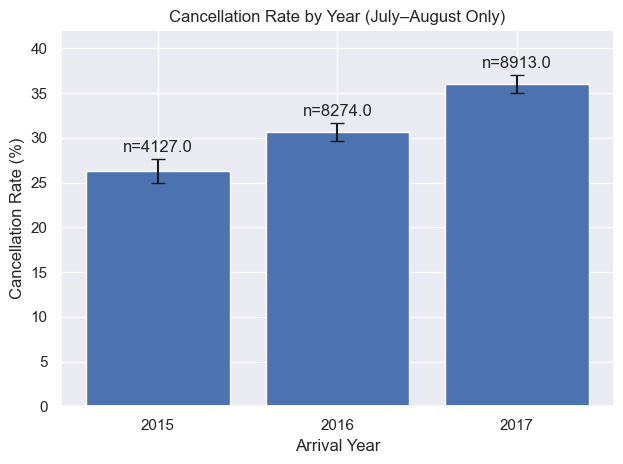

In [121]:
plt.bar(
    b3_summary["ArrivalDateYear"].astype(str),
    b3_summary["rate_percent"],
    yerr=[
        b3_summary["rate_percent"] - b3_summary["ci_low_percent"],
        b3_summary["ci_high_percent"] - b3_summary["rate_percent"]
    ],
    capsize=5
)

for i, row in b3_summary.iterrows():
    plt.text(
        i,
        row["ci_high_percent"] + 0.8,
        f'n={row["n"]}',
        ha="center"
    )

plt.xlabel("Arrival Year")
plt.ylabel("Cancellation Rate (%)")
plt.title("Cancellation Rate by Year (July–August Only)")
plt.ylim(0, 42)
plt.tight_layout()

plt.savefig(
    "../outputs/figures/p2_cancellation_year_july_august.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

For July–August arrivals, the cancellation rate increased consistently across the three years, from approximately 26.1% in 2015 to 30.4% in 2016 and 35.8% in 2017. This indicates a substantial increase in cancellation rates for these peak summer months over time.

**Question:** Does the cancellation rate differ across years when comparing the same months?

**Observation:** The cancellation rate for July and August differs across 2015, 2016, and 2017. The sample size (n) and 95% confidence intervals are shown for each year.

**Possible explanation:** The differences may be linked to changes in booking patterns, customer mix, or market conditions across years. These factors are possible explanations, not proof of causation.

**Statistical question:** Is there evidence that cancellation rates differ across the three years when the comparison is restricted to July and August?

### E4.1 — Chi-Square Test: Repeated Guest Status vs Cancellation

To determine whether cancellation status is statistically associated with whether a guest is a repeated guest, a **Chi-Square Test of Independence** was performed between `IsRepeatedGuest` and `IsCanceled`. Both variables are categorical, making the chi-square test appropriate for assessing their association.

### E4.1 Statistical Test: Repeated Guest Status and Cancellation

**Question:** Is cancellation status statistically associated with whether a guest is a repeated guest?

**Test:** A chi-square test of independence is used because both variables are categorical.

**Why this test:** The test compares the observed cancellation counts for repeated and non-repeated guests with the counts expected if the two variables were independent.

**Interpretation:** A small p-value provides evidence of an association between repeated guest status and cancellation. This does not prove that repeated guest status causes cancellation.

In [104]:
repeated_guest_table = pd.crosstab(
    df["IsRepeatedGuest"],
    df["IsCanceled"]
)

print("Contingency table:")
print(repeated_guest_table)

Contingency table:
IsCanceled           0      1
IsRepeatedGuest              
0                60217  23764
1                 3154    261


In [105]:
chi2, p_value, dof, expected = stats.chi2_contingency(
    repeated_guest_table
)

print(f"Chi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"p-value: {p_value:.6g}")

Chi-square statistic: 701.2646
Degrees of freedom: 1
p-value: 1.58748e-154


In [106]:
e4_results = []

e4_results.append({
    "Test": "Repeated guest status vs cancellation",
    "Test_Type": "Chi-square test of independence",
    "Statistic": chi2,
    "p_value": p_value
})

pd.DataFrame(e4_results)

,Test,Test_Type,Statistic,p_value
0,Repeated guest status vs cancellation,Chi-square test of independence,701.264597,1.587485e-154


**Interpretation:** The chi-square test produced a statistic of **701.2646** with **1 degree of freedom** and a p-value of **1.58748 × 10⁻¹⁵⁴**. Since the p-value is far below the significance level of 0.05, the null hypothesis of independence is rejected. Therefore, there is strong statistical evidence of an association between **repeated guest status and booking cancellation**. This result indicates association and does not imply that repeated guest status directly causes or prevents cancellation.

### E4.2 — Chi-Square Test: Online TA vs Direct and Cancellation

To investigate whether the booking channel is associated with cancellation status, a **Chi-Square Test of Independence** is performed between the `MarketSegment` and `IsCanceled` variables. The analysis focuses specifically on bookings from the **Online TA** and **Direct** market segments. This test determines whether the observed cancellation patterns differ significantly between these two booking channels.

In [107]:
# E4.2: Online TA vs Direct

online_direct_df = df[
    df["MarketSegment"].isin(["Online TA", "Direct"])
].copy()

online_direct_table = pd.crosstab(
    online_direct_df["MarketSegment"],
    online_direct_df["IsCanceled"]
)

print("Contingency table: Online TA vs Direct")
print(online_direct_table)


chi2, p_value, dof, expected = stats.chi2_contingency(
    online_direct_table
)

print("\nChi-square statistic:", f"{chi2:.4f}")
print("Degrees of freedom:", dof)
print("p-value:", f"{p_value:.6g}")


# Add result to E4 results
e4_results.append({
    "Test": "Online TA vs Direct and cancellation",
    "Test_Type": "Chi-square test of independence",
    "Statistic": chi2,
    "p_value": p_value
})

Contingency table: Online TA vs Direct
IsCanceled         0      1
MarketSegment              
Direct         10067   1737
Online TA      33373  18245

Chi-square statistic: 1893.8975
Degrees of freedom: 1
p-value: 0


In [108]:
pd.crosstab(
    online_direct_df["MarketSegment"],
    online_direct_df["IsCanceled"]
)

IsCanceled,0,1
MarketSegment,,
Direct,10067,1737
Online TA,33373,18245


In [109]:
pd.DataFrame(e4_results)

,Test,Test_Type,Statistic,p_value
0,Repeated guest status vs cancellation,Chi-square test of independence,701.264597,1.587485e-154
1,Online TA vs Direct and cancellation,Chi-square test of independence,1893.897539,0.000000e+00


**Interpretation:** The Chi-Square Test of Independence produced a chi-square statistic of **1893.8975** with **1 degree of freedom** and an extremely small p-value (displayed as **0**). Since the p-value is far below the 0.05 significance level, the null hypothesis of independence is rejected. Therefore, there is strong statistical evidence of an association between **market segment (Online TA vs Direct)** and **booking cancellation status**. The observed cancellation patterns differ significantly between the two booking channels. This result indicates an association and does not establish a causal relationship.

Market Segment vs Cancellation

In [110]:
# E4.3 — Market Segment vs Cancellation
# Chi-square test of independence

market_segment_table = pd.crosstab(
    df["MarketSegment"],
    df["IsCanceled"]
)

print("Contingency table: Market Segment vs Cancellation")
print(market_segment_table)

chi2, p_value, dof, expected = stats.chi2_contingency(
    market_segment_table
)

print(f"\nChi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"p-value: {p_value:.6g}")

Contingency table: Market Segment vs Cancellation
IsCanceled         0      1
MarketSegment              
Aviation         182     45
Complementary    614     88
Corporate       3702    510
Direct         10067   1737
Groups          3607   1335
Offline TA/TO  11826   2063
Online TA      33373  18245
Undefined          0      2

Chi-square statistic: 4268.5709
Degrees of freedom: 7
p-value: 0


In [111]:
# Cramér's V — effect size

n = market_segment_table.to_numpy().sum()
min_dim = min(
    market_segment_table.shape[0] - 1,
    market_segment_table.shape[1] - 1
)

cramers_v = np.sqrt(chi2 / (n * min_dim))

print(f"Cramér's V: {cramers_v:.4f}")

Cramér's V: 0.2210


Previous Cancellation History vs Current Cancellation

In [112]:
# E4.4 — Previous Cancellation History vs Current Cancellation

import pandas as pd
from scipy import stats

# Create contingency table
previous_cancel_table = pd.crosstab(
    df["PreviousCancellationHistory"],
    df["IsCanceled"]
)

print("Contingency table: Previous Cancellation History vs Current Cancellation")
print(previous_cancel_table)

# Chi-square test of independence
chi2, p_value, dof, expected = stats.chi2_contingency(
    previous_cancel_table
)

print(f"\nChi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"p-value: {p_value:.6g}")

Contingency table: Previous Cancellation History vs Current Cancellation
IsCanceled                              0      1
PreviousCancellationHistory                     
At Least One Previous Cancellation    541   1144
No Previous Cancellations           62830  22881

Chi-square statistic: 1405.0146
Degrees of freedom: 1
p-value: 1.70903e-307


In [113]:
# Cancellation rates by previous cancellation history

previous_cancel_rates = (
    df.groupby("PreviousCancellationHistory")["IsCanceled"]
    .agg(
        cancelled="sum",
        n="count",
        rate="mean"
    )
    .reset_index()
)

previous_cancel_rates["rate_percent"] = (
    previous_cancel_rates["rate"] * 100
)

print(previous_cancel_rates)

          PreviousCancellationHistory  cancelled      n      rate  \
0  At Least One Previous Cancellation       1144   1685  0.678932   
1           No Previous Cancellations      22881  85711  0.266955   

   rate_percent  
0     67.893175  
1     26.695523  


In [114]:
# Cramér's V effect size

n = previous_cancel_table.to_numpy().sum()

min_dim = min(
    previous_cancel_table.shape[0] - 1,
    previous_cancel_table.shape[1] - 1
)

cramers_v = np.sqrt(
    chi2 / (n * min_dim)
)

print(f"Cramér's V: {cramers_v:.4f}")

Cramér's V: 0.1268


ADR by Hotel

In [115]:
# E4.5 — ADR by Hotel

import numpy as np
from scipy import stats

# Separate ADR values by hotel
city_adr = df.loc[
    df["Hotel"] == "City Hotel",
    "ADR"
].dropna()

resort_adr = df.loc[
    df["Hotel"] == "Resort Hotel",
    "ADR"
].dropna()

# Descriptive statistics
print("ADR by Hotel")
print("------------------------------")
print(f"City Hotel   : n={len(city_adr)}, mean={city_adr.mean():.2f}, "
      f"SD={city_adr.std():.2f}")

print(f"Resort Hotel : n={len(resort_adr)}, mean={resort_adr.mean():.2f}, "
      f"SD={resort_adr.std():.2f}")

# Welch's independent two-sample t-test
t_stat, p_value = stats.ttest_ind(
    city_adr,
    resort_adr,
    equal_var=False
)

print("\nWelch's t-test")
print("------------------------------")
print(f"t-statistic: {t_stat:.4f}")
print(f"p-value: {p_value:.6g}")

ADR by Hotel
------------------------------
City Hotel   : n=53428, mean=110.99, SD=48.06
Resort Hotel : n=33968, mean=99.03, SD=63.76

Welch's t-test
------------------------------
t-statistic: 29.6248
p-value: 1.91652e-191


In [116]:
# Mean difference: City Hotel - Resort Hotel

mean_difference = city_adr.mean() - resort_adr.mean()

print(f"\nMean ADR difference (City - Resort): {mean_difference:.2f}")


Mean ADR difference (City - Resort): 11.96


In [117]:
# Cohen's d effect size

n_city = len(city_adr)
n_resort = len(resort_adr)

pooled_sd = np.sqrt(
    (
        (n_city - 1) * city_adr.var()
        + (n_resort - 1) * resort_adr.var()
    )
    / (n_city + n_resort - 2)
)

cohens_d = mean_difference / pooled_sd

print(f"Cohen's d: {cohens_d:.4f}")

Cohen's d: 0.2186


In [118]:
# 95% CI for the difference in mean ADR
# Welch-Satterthwaite degrees of freedom

city_mean = city_adr.mean()
resort_mean = resort_adr.mean()

city_var = city_adr.var()
resort_var = resort_adr.var()

se = np.sqrt(
    city_var / n_city +
    resort_var / n_resort
)

welch_df = (
    (city_var / n_city + resort_var / n_resort) ** 2
    /
    (
        (city_var / n_city) ** 2 / (n_city - 1)
        +
        (resort_var / n_resort) ** 2 / (n_resort - 1)
    )
)

t_critical = stats.t.ppf(0.975, welch_df)

ci_low = mean_difference - t_critical * se
ci_high = mean_difference + t_critical * se

print(f"95% CI for mean difference: [{ci_low:.2f}, {ci_high:.2f}]")
print(f"Welch degrees of freedom: {welch_df:.2f}")

95% CI for mean difference: [11.17, 12.75]
Welch degrees of freedom: 58116.40


Interpretation
There is a statistically significant difference in ADR between City Hotel and Resort Hotel, since:

p < 0.001

City Hotel has a higher average ADR:
- City Hotel: 110.99
- Resort Hotel: 99.03
- Difference: 11.96
The 95% confidence interval for the difference is [11.17, 12.75], which does not include zero, supporting the conclusion that the difference is statistically significant.

However, Cohen's d = 0.2186, indicating that the practical effect is relatively small despite the extremely strong statistical significance. This is important because the dataset is very large, so even relatively modest differences can produce extremely small p-values.

### E4 — Statistical Test Summary

| Test | Statistical Test | Statistic | p-value | Effect Size |
|---|---|---:|---:|---:|
| Repeated Guest vs Cancellation | Chi-square | 701.2646 | 1.58748 × 10⁻¹⁵⁴ | — |
| Online TA vs Direct vs Cancellation | Chi-square | 1893.8975 | < 1 × 10⁻³⁰⁰ | — |
| Market Segment vs Cancellation | Chi-square | 4268.5709 | < 1 × 10⁻³⁰⁰ | Cramér's V = 0.2210 |
| Previous Cancellation History vs Cancellation | Chi-square | 1405.0146 | 1.70903 × 10⁻³⁰⁷ | Cramér's V = 0.1268 |
| ADR by Hotel | Welch's t-test | 29.6248 | 1.91652 × 10⁻¹⁹¹ | Cohen's d = 0.2186 |


All five tests produced statistically significant results at the 0.05 significance level. The p-values from these tests will be provided to Person 3 for the multiple-testing correction in E5. Statistical significance indicates evidence of association or difference, while the reported effect sizes provide additional information about the magnitude of the observed effects.